In [8]:

# ==========================================
# PROBLEM 1: RNN, LSTM AND GRU
# Section 1: Environment Setup
# ==========================================

import os
import csv
import random
import time
import copy
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All required libraries imported successfully!")


All required libraries imported successfully!


In [9]:

# Three experiment seeds selected for reproducibility
EXPERIMENT_SEEDS = [42, 123, 2026]

# Exact seeds specified by the instructor
ADDING_TRAIN_SEED = 0
ADDING_VAL_SEED = 1
ADDING_TEST_SEED = 2

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(EXPERIMENT_SEEDS[0])

print("Experiment seeds:", EXPERIMENT_SEEDS)
print("Adding training seed:", ADDING_TRAIN_SEED)
print("Adding validation seed:", ADDING_VAL_SEED)
print("Adding test seed:", ADDING_TEST_SEED)


Experiment seeds: [42, 123, 2026]
Adding training seed: 0
Adding validation seed: 1
Adding test seed: 2


In [10]:
from pathlib import Path

BASE_DIR = Path("DNN_Assignment")
FIGURES_DIR = BASE_DIR / "figures"

BASE_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RESULTS_FILE = BASE_DIR / "results.csv"

In [11]:

# Create project directories


FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("Output directory structure created.")

for folder in [BASE_DIR, FIGURES_DIR]:
    print(folder)



Output directory structure created.
DNN_Assignment
DNN_Assignment/figures


In [ ]:

# RESULT_COLUMNS = [
#     "problem",
#     "model",
#     "seed",
#     "seq_len",
#     "test_acc",
#     "macro_f1",
#     "test_mse",
#     "params",
#     "sec_per_epoch",
#     "val_loss_nats",
#     "bits_per_char",
#     "notes"
# ]

# RESULTS_FILE = "results.csv"

# def initialise_results():

#     with open(RESULTS_FILE, "w", newline="") as file:

#         writer = csv.DictWriter(
#             file,
#             fieldnames=RESULT_COLUMNS
#         )

#         writer.writeheader()


# initialise_results()

# print("Results file initialised.")
# print("Required columns:", len(RESULT_COLUMNS))


import csv
from pathlib import Path

# Define the columns used to store experiment results
RESULT_COLUMNS = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes"
]

# # Define relative assignment paths
# BASE_DIR = Path("DNN_Assignment")
# FIGURES_DIR = BASE_DIR / "figures"
# RESULTS_FILE = BASE_DIR / "results.csv"

# # Create directories if they do not exist
# BASE_DIR.mkdir(parents=True, exist_ok=True)
# FIGURES_DIR.mkdir(parents=True, exist_ok=True)


# Initialize results CSV only if it does not already exist
def initialise_results():

    if not RESULTS_FILE.exists() or RESULTS_FILE.stat().st_size == 0:

        with open(RESULTS_FILE, "w", newline="") as file:
            writer = csv.DictWriter(
                file,
                fieldnames=RESULT_COLUMNS
            )
            writer.writeheader()

        print("New results file initialized.")

    else:
        print("Existing results file found. Previous results preserved.")


initialise_results()

print("Results file:", RESULTS_FILE)
print("Figures folder:", FIGURES_DIR)
print("Required columns:", len(RESULT_COLUMNS))


# Function to append experiment results to CSV
def save_result(result):

    # Fill missing metrics with empty values
    row = {
        column: result.get(column, "")
        for column in RESULT_COLUMNS
    }

    with open(RESULTS_FILE, "a", newline="") as file:

        writer = csv.DictWriter(
            file,
            fieldnames=RESULT_COLUMNS
        )

        writer.writerow(row)


print("Experiment result-saving function ready.")


Results file initialised.
Required columns: 12


In [11]:

# ==========================================
# Section 2: HAR Dataset Download
# ==========================================

har_url = (
    "https://archive.ics.uci.edu/static/public/240/"
    "human+activity+recognition+using+smartphones.zip"
)

archive_name = "har.zip"

if not os.path.exists(archive_name):

    print("Downloading UCI HAR dataset...")

    urllib.request.urlretrieve(
        har_url,
        archive_name
    )

    print("Download completed!")

else:
    print("Dataset archive already exists.")

# Extract outer archive
with zipfile.ZipFile(archive_name, "r") as zip_file:
    zip_file.extractall("har")

# Extract inner archive if present
nested_archive = "har/UCI HAR Dataset.zip"

if os.path.exists(nested_archive):

    with zipfile.ZipFile(nested_archive, "r") as zip_file:
        zip_file.extractall("har")

print("Dataset extraction completed!")


Download completed!
Dataset extraction completed!


In [12]:

HAR_PATH = "har/UCI HAR Dataset"

# Verify required folders and files
required_paths = [
    os.path.join(HAR_PATH, "train", "Inertial Signals"),
    os.path.join(HAR_PATH, "test", "Inertial Signals"),
    os.path.join(HAR_PATH, "train", "y_train.txt"),
    os.path.join(HAR_PATH, "test", "y_test.txt"),
    os.path.join(HAR_PATH, "train", "subject_train.txt"),
    os.path.join(HAR_PATH, "test", "subject_test.txt")
]

for path in required_paths:
    assert os.path.exists(path), f"Missing: {path}"

print("HAR dataset structure verified successfully!")

print("Training folder:", os.path.exists(
    os.path.join(HAR_PATH, "train")
))

print("Testing folder:", os.path.exists(
    os.path.join(HAR_PATH, "test")
))


HAR dataset structure verified successfully!
Training folder: True
Testing folder: True


In [13]:

# Fixed sensor channel order as specified in the assignment

sensor_channels = [
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z",
    "total_acc_x",
    "total_acc_y",
    "total_acc_z"
]

activity_labels = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

assert len(sensor_channels) == 9
assert len(activity_labels) == 6

print("Sensor channels:", len(sensor_channels))
print("Activity classes:", len(activity_labels))
print("Channel order verified.")


Sensor channels: 9
Activity classes: 6
Channel order verified.


In [14]:

def load_sensor_sequences(split):

    signal_directory = os.path.join(
        HAR_PATH,
        split,
        "Inertial Signals"
    )

    collected_channels = []

    for channel_name in sensor_channels:

        signal_file = os.path.join(
            signal_directory,
            f"{channel_name}_{split}.txt"
        )

        readings = np.loadtxt(signal_file)

        assert readings.ndim == 2
        assert readings.shape[1] == 128

        collected_channels.append(readings)

    # Stack channels along the final dimension
    # Result: (samples, 128, 9)
    sequence_array = np.stack(
        collected_channels,
        axis=-1
    ).astype(np.float32)

    label_array = np.loadtxt(
        os.path.join(HAR_PATH, split, f"y_{split}.txt")
    ).astype(np.int64)

    subject_array = np.loadtxt(
        os.path.join(HAR_PATH, split, f"subject_{split}.txt")
    ).astype(np.int64)

    return sequence_array, label_array, subject_array


In [15]:

# Test the loading function on both splits

sample_train_x, sample_train_y, sample_train_subjects = (
    load_sensor_sequences("train")
)

sample_test_x, sample_test_y, sample_test_subjects = (
    load_sensor_sequences("test")
)

assert sample_train_x.shape == (7352, 128, 9)
assert sample_test_x.shape == (2947, 128, 9)

assert sample_train_y.shape == (7352,)
assert sample_test_y.shape == (2947,)

assert sample_train_subjects.shape == (7352,)
assert sample_test_subjects.shape == (2947,)

assert np.isfinite(sample_train_x).all()
assert np.isfinite(sample_test_x).all()

print("HAR loading tests passed!")
print("Training:", sample_train_x.shape)
print("Testing:", sample_test_x.shape)


HAR loading tests passed!
Training: (7352, 128, 9)
Testing: (2947, 128, 9)


In [16]:

def split_by_subject(features, labels, subject_ids, seed):

    unique_ids = np.unique(subject_ids)

    # Select four subjects for validation
    rng = np.random.default_rng(seed)

    validation_ids = rng.choice(
        unique_ids,
        size=4,
        replace=False
    )

    validation_mask = np.isin(
        subject_ids,
        validation_ids
    )

    training_mask = ~validation_mask

    X_tr = features[training_mask]
    y_tr = labels[training_mask]

    X_val = features[validation_mask]
    y_val = labels[validation_mask]

    train_ids = subject_ids[training_mask]
    val_ids = subject_ids[validation_mask]

    return (
        X_tr, y_tr,
        X_val, y_val,
        train_ids, val_ids,
        validation_ids
    )


In [17]:

# Test the splitting function using the first experiment seed

split_output = split_by_subject(
    sample_train_x,
    sample_train_y,
    sample_train_subjects,
    EXPERIMENT_SEEDS[0]
)

X_train_raw, y_train, X_val_raw, y_val = split_output[:4]

train_subject_ids = split_output[4]
val_subject_ids = split_output[5]
selected_val_subjects = split_output[6]

# Exactly four validation subjects
assert len(selected_val_subjects) == 4

# No subject overlap
assert len(
    set(train_subject_ids) & set(val_subject_ids)
) == 0

# Every selected validation subject belongs to validation
assert set(val_subject_ids) == set(selected_val_subjects)

# All samples are accounted for
assert len(X_train_raw) + len(X_val_raw) == 7352

print("Subject-wise split tests passed!")
print("Selected validation subjects:", selected_val_subjects)
print("Training shape:", X_train_raw.shape)
print("Validation shape:", X_val_raw.shape)


Subject-wise split tests passed!
Selected validation subjects: [16  3 22 23]
Training shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)


In [18]:

def normalise_sensor_data(train_data, val_data, test_data):

    # Calculate channel statistics from training data only
    # Shape of mean and std: (1, 1, 9)

    channel_mean = np.mean(
        train_data,
        axis=(0, 1),
        keepdims=True
    )

    channel_std = np.std(
        train_data,
        axis=(0, 1),
        keepdims=True
    )

    # Prevent division by zero
    channel_std = np.maximum(channel_std, 1e-8)

    # Apply training statistics to all three datasets
    train_scaled = (train_data - channel_mean) / channel_std
    val_scaled = (val_data - channel_mean) / channel_std
    test_scaled = (test_data - channel_mean) / channel_std

    return (
        train_scaled.astype(np.float32),
        val_scaled.astype(np.float32),
        test_scaled.astype(np.float32),
        channel_mean,
        channel_std
    )


In [19]:

# Use a small sample of the training data to test normalisation
test_train = X_train_raw[:100]
test_val = X_val_raw[:50]
test_test = sample_test_x[:50]

scaled_train, scaled_val, scaled_test, test_mean, test_std = (
    normalise_sensor_data(
        test_train,
        test_val,
        test_test
    )
)

# Verify output dimensions
assert scaled_train.shape == test_train.shape
assert scaled_val.shape == test_val.shape
assert scaled_test.shape == test_test.shape

# Verify training mean is approximately zero
assert np.allclose(
    scaled_train.mean(axis=(0, 1)),
    0,
    atol=1e-5
)

# Verify training standard deviation is approximately one
assert np.allclose(
    scaled_train.std(axis=(0, 1)),
    1,
    atol=1e-5
)

# Verify there are no invalid values
assert np.isfinite(scaled_train).all()
assert np.isfinite(scaled_val).all()
assert np.isfinite(scaled_test).all()

print("Normalisation tests passed!")


Normalisation tests passed!


In [20]:

X_train, X_val, X_test, har_mean, har_std = (
    normalise_sensor_data(
        X_train_raw,
        X_val_raw,
        sample_test_x
    )
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_val.shape)
print("Test shape:", X_test.shape)

print("\nTraining channel means:")
print(X_train.mean(axis=(0, 1)))

print("\nTraining channel standard deviations:")
print(X_train.std(axis=(0, 1)))


Training shape: (5952, 128, 9)
Validation shape: (1400, 128, 9)
Test shape: (2947, 128, 9)

Training channel means:
[ 1.0838423e-07 -2.1822865e-08  2.4065425e-10  6.7427003e-08
  6.4782938e-08 -9.4826849e-09  3.3542012e-05  7.8668357e-08
  1.2749171e-06]

Training channel standard deviations:
[0.99999005 1.000006   1.000001   0.99997765 0.99997425 1.0000191
 0.9998641  1.0001482  0.99996763]


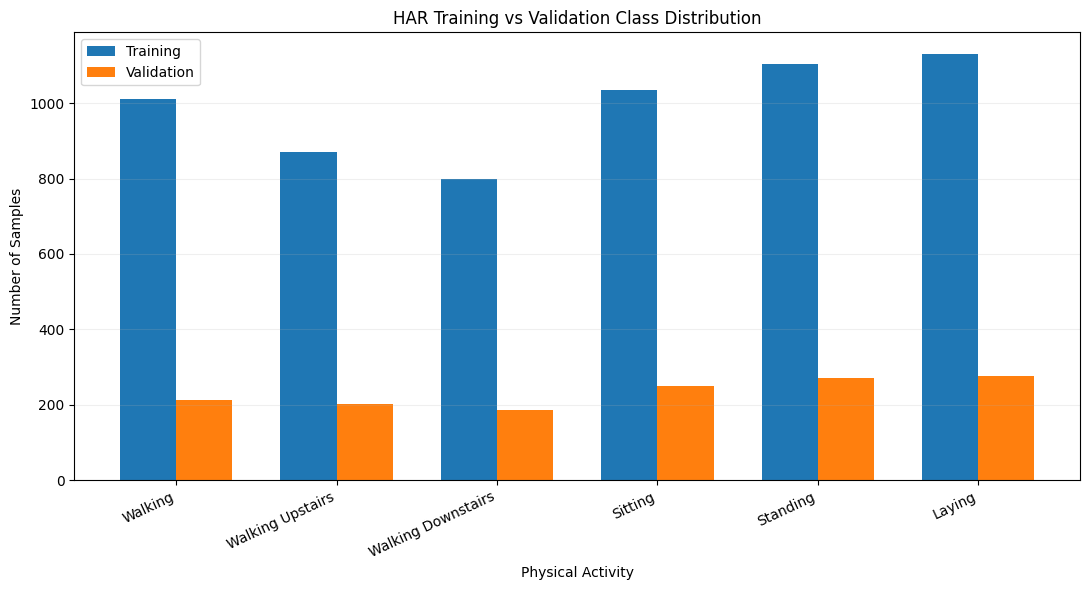

In [21]:

# Count samples belonging to each activity
train_class_counts = np.bincount(
    y_train,
    minlength=7
)[1:]

validation_class_counts = np.bincount(
    y_val,
    minlength=7
)[1:]

positions = np.arange(6)
bar_width = 0.35

plt.figure(figsize=(11, 6))

plt.bar(
    positions - bar_width / 2,
    train_class_counts,
    bar_width,
    label="Training"
)

plt.bar(
    positions + bar_width / 2,
    validation_class_counts,
    bar_width,
    label="Validation"
)

plt.xticks(
    positions,
    activity_labels,
    rotation=25,
    ha="right"
)

plt.xlabel("Physical Activity")
plt.ylabel("Number of Samples")
plt.title("HAR Training vs Validation Class Distribution")

plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"har_class_distribution.png",
    dpi=300
)


plt.show()


In [ ]:

assert len(train_class_counts) == 6
assert len(validation_class_counts) == 6

assert train_class_counts.sum() == len(y_train)
assert validation_class_counts.sum() == len(y_val)

print("Class distribution verification passed!")

print("\nTraining class counts:")
for name, count in zip(activity_labels, train_class_counts):
    print(f"{name}: {count}")

print("\nValidation class counts:")
for name, count in zip(activity_labels, validation_class_counts):
    print(f"{name}: {count}")


Class distribution verification passed!

Training class counts:
Walking: 1012
Walking Upstairs: 870
Walking Downstairs: 800
Sitting: 1035
Standing: 1104
Laying: 1131

Validation class counts:
Walking: 214
Walking Upstairs: 203
Walking Downstairs: 186
Sitting: 251
Standing: 270
Laying: 276


In [ ]:

def make_adding(n, T, seed):

    rng = np.random.default_rng(seed)

    x = np.zeros((n, T, 2), dtype=np.float32)

    # Generate random values in channel 0
    x[:, :, 0] = rng.random((n, T))

    # Select one marker position in each half
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    rows = np.arange(n)

    # Mark the selected positions in channel 1
    x[rows, i1, 1] = 1
    x[rows, i2, 1] = 1

    # Calculate target using marked values
    y = x[rows, i1, 0] + x[rows, i2, 0]

    return x, y.astype(np.float32)


In [ ]:

sample_x, sample_y = make_adding(
    n=1000,
    T=100,
    seed=0
)

markers = sample_x[:, :, 1]

# Every sequence must have exactly two markers
assert np.all(markers.sum(axis=1) == 2)

# One marker in each half
assert np.all(markers[:, :50].sum(axis=1) == 1)
assert np.all(markers[:, 50:].sum(axis=1) == 1)

# Verify target calculation
expected_y = (sample_x[:, :, 0] * markers).sum(axis=1)

assert np.allclose(sample_y, expected_y, atol=1e-6)

assert sample_x.shape == (1000, 100, 2)
assert sample_y.shape == (1000,)

print("Adding problem generator tests passed!")


Adding problem generator tests passed!


In [ ]:

sequence_lengths = [50, 100, 200, 400]

adding_datasets = {}

for T in sequence_lengths:

    train_x, train_y = make_adding(10000, T, 0)
    val_x, val_y = make_adding(1000, T, 1)
    test_x, test_y = make_adding(1000, T, 2)

    adding_datasets[T] = {
        "train": (train_x, train_y),
        "validation": (val_x, val_y),
        "test": (test_x, test_y)
    }

    print(
        f"T={T} | Train: {train_x.shape} | "
        f"Validation: {val_x.shape} | Test: {test_x.shape}"
    )


T=50 | Train: (10000, 50, 2) | Validation: (1000, 50, 2) | Test: (1000, 50, 2)
T=100 | Train: (10000, 100, 2) | Validation: (1000, 100, 2) | Test: (1000, 100, 2)
T=200 | Train: (10000, 200, 2) | Validation: (1000, 200, 2) | Test: (1000, 200, 2)
T=400 | Train: (10000, 400, 2) | Validation: (1000, 400, 2) | Test: (1000, 400, 2)


In [ ]:

for T in sequence_lengths:

    _, actual_y = adding_datasets[T]["test"]

    predictions = np.ones_like(actual_y)

    mse = np.mean((predictions - actual_y) ** 2)

    print(f"T={T} | Baseline MSE: {mse:.5f}")

    assert 0.14 < mse < 0.19

print("Baseline verification passed!")


T=50 | Baseline MSE: 0.17539
T=100 | Baseline MSE: 0.16971
T=200 | Baseline MSE: 0.16794
T=400 | Baseline MSE: 0.15272
Baseline verification passed!


In [32]:

# ==========================================
# TASK 2: CUSTOM RECURRENT CELLS
# ==========================================
import torch

# Select GPU if available, otherwise use CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
INPUT_SIZE = 9
HIDDEN_SIZE = 64

CHECK_BATCH = 8
CHECK_SEQUENCE_LENGTH = 12

print("Input features:", INPUT_SIZE)
print("Hidden units:", HIDDEN_SIZE)
print("Verification batch size:", CHECK_BATCH)
print("Verification sequence length:", CHECK_SEQUENCE_LENGTH)
print("Computation device:", device)


Input features: 9
Hidden units: 64
Verification batch size: 8
Verification sequence length: 12
Computation device: cuda


In [33]:

class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):

        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Weight shapes follow PyTorch's reference layout
        self.weight_ih = nn.Parameter(
            torch.empty(hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.zeros(hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.zeros(hidden_size)
        )

        nn.init.xavier_uniform_(self.weight_ih)
        nn.init.orthogonal_(self.weight_hh)

    def forward(self, current_input, previous_hidden):

        # current_input: (batch_size, input_size)
        # previous_hidden: (batch_size, hidden_size)

        input_transform = F.linear(
            current_input,
            self.weight_ih,
            self.bias_ih
        )

        hidden_transform = F.linear(
            previous_hidden,
            self.weight_hh,
            self.bias_hh
        )

        # Both transformations have shape (batch_size, hidden_size)
        updated_hidden = torch.tanh(
            input_transform + hidden_transform
        )

        return updated_hidden


In [34]:

def test_rnn_cell():

    torch.manual_seed(42)

    rnn_unit = MyRNNCell(
        INPUT_SIZE,
        HIDDEN_SIZE
    ).to(device)

    sample_input = torch.randn(
        CHECK_BATCH,
        INPUT_SIZE,
        device=device
    )

    previous_hidden = torch.zeros(
        CHECK_BATCH,
        HIDDEN_SIZE,
        device=device
    )

    calculated_hidden = rnn_unit(
        sample_input,
        previous_hidden
    )

    assert calculated_hidden.shape == (
        CHECK_BATCH,
        HIDDEN_SIZE
    )

    assert torch.isfinite(calculated_hidden).all()

    print("MyRNNCell unit test passed!")


test_rnn_cell()


MyRNNCell unit test passed!


In [35]:

class MyLSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):

        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Four gates: input, forget, candidate and output
        self.weight_ih = nn.Parameter(
            torch.empty(4 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(4 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.zeros(4 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.zeros(4 * hidden_size)
        )

        nn.init.xavier_uniform_(self.weight_ih)
        nn.init.orthogonal_(self.weight_hh)

    def forward(self, current_input, previous_state):

        previous_hidden, previous_cell = previous_state

        # current_input: (batch_size, input_size)
        # previous_hidden: (batch_size, hidden_size)
        # previous_cell: (batch_size, hidden_size)

        input_part = F.linear(
            current_input,
            self.weight_ih,
            self.bias_ih
        )

        hidden_part = F.linear(
            previous_hidden,
            self.weight_hh,
            self.bias_hh
        )

        # Combined gates: (batch_size, 4 * hidden_size)
        all_gates = input_part + hidden_part

        # Split into four tensors, each (batch_size, hidden_size)
        input_gate, forget_gate, candidate_gate, output_gate = (
            all_gates.chunk(4, dim=1)
        )

        input_gate = torch.sigmoid(input_gate)
        forget_gate = torch.sigmoid(forget_gate)
        candidate_gate = torch.tanh(candidate_gate)
        output_gate = torch.sigmoid(output_gate)

        # Update long-term memory
        new_cell = (
            forget_gate * previous_cell
            + input_gate * candidate_gate
        )

        # Calculate new hidden state
        new_hidden = (
            output_gate * torch.tanh(new_cell)
        )

        return new_hidden, new_cell


In [36]:

def test_lstm_cell():

    torch.manual_seed(42)

    lstm_unit = MyLSTMCell(
        INPUT_SIZE,
        HIDDEN_SIZE
    ).to(device)

    sample_input = torch.randn(
        CHECK_BATCH,
        INPUT_SIZE,
        device=device
    )

    initial_hidden = torch.zeros(
        CHECK_BATCH,
        HIDDEN_SIZE,
        device=device
    )

    initial_cell = torch.zeros(
        CHECK_BATCH,
        HIDDEN_SIZE,
        device=device
    )

    new_hidden, new_cell = lstm_unit(
        sample_input,
        (initial_hidden, initial_cell)
    )

    assert new_hidden.shape == (CHECK_BATCH, HIDDEN_SIZE)
    assert new_cell.shape == (CHECK_BATCH, HIDDEN_SIZE)

    assert torch.isfinite(new_hidden).all()
    assert torch.isfinite(new_cell).all()

    print("MyLSTMCell unit test passed!")


test_lstm_cell()


MyLSTMCell unit test passed!


In [37]:

class MyGRUCell(nn.Module):

    def __init__(self, input_size, hidden_size):

        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Three gates: reset, update and candidate
        self.weight_ih = nn.Parameter(
            torch.empty(3 * hidden_size, input_size)
        )

        self.weight_hh = nn.Parameter(
            torch.empty(3 * hidden_size, hidden_size)
        )

        self.bias_ih = nn.Parameter(
            torch.zeros(3 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.zeros(3 * hidden_size)
        )

        nn.init.xavier_uniform_(self.weight_ih)
        nn.init.orthogonal_(self.weight_hh)

    def forward(self, current_input, previous_hidden):

        # current_input: (batch_size, input_size)
        # previous_hidden: (batch_size, hidden_size)

        input_part = F.linear(
            current_input,
            self.weight_ih,
            self.bias_ih
        )

        hidden_part = F.linear(
            previous_hidden,
            self.weight_hh,
            self.bias_hh
        )

        # Each gate has shape (batch_size, hidden_size)
        input_reset, input_update, input_candidate = (
            input_part.chunk(3, dim=1)
        )

        hidden_reset, hidden_update, hidden_candidate = (
            hidden_part.chunk(3, dim=1)
        )

        # Reset gate
        reset_gate = torch.sigmoid(
            input_reset + hidden_reset
        )

        # Update gate
        update_gate = torch.sigmoid(
            input_update + hidden_update
        )

        # Candidate hidden state
        candidate_hidden = torch.tanh(
            input_candidate
            + reset_gate * hidden_candidate
        )

        # Final hidden state
        new_hidden = (
            (1 - update_gate) * candidate_hidden
            + update_gate * previous_hidden
        )

        return new_hidden


In [38]:

def test_gru_cell():

    torch.manual_seed(42)

    gru_unit = MyGRUCell(
        INPUT_SIZE,
        HIDDEN_SIZE
    ).to(device)

    sample_input = torch.randn(
        CHECK_BATCH,
        INPUT_SIZE,
        device=device
    )

    previous_hidden = torch.zeros(
        CHECK_BATCH,
        HIDDEN_SIZE,
        device=device
    )

    updated_hidden = gru_unit(
        sample_input,
        previous_hidden
    )

    assert updated_hidden.shape == (
        CHECK_BATCH,
        HIDDEN_SIZE
    )

    assert torch.isfinite(updated_hidden).all()

    print("MyGRUCell unit test passed!")


test_gru_cell()


MyGRUCell unit test passed!


In [39]:

# ==========================================
# NUMERICAL EQUIVALENCE VERIFICATION
# ==========================================

torch.manual_seed(123)

reference_rnn = nn.RNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    nonlinearity="tanh",
    batch_first=True
).to(device)

reference_lstm = nn.LSTM(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    batch_first=True
).to(device)

reference_gru = nn.GRU(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    num_layers=1,
    batch_first=True
).to(device)

# Create corresponding custom cells
custom_rnn = MyRNNCell(
    INPUT_SIZE, HIDDEN_SIZE
).to(device)

custom_lstm = MyLSTMCell(
    INPUT_SIZE, HIDDEN_SIZE
).to(device)

custom_gru = MyGRUCell(
    INPUT_SIZE, HIDDEN_SIZE
).to(device)

print("Reference and custom models created.")


Reference and custom models created.


In [ ]:

torch.manual_seed(456)

sequence_input = torch.randn(
    CHECK_BATCH,
    CHECK_SEQUENCE_LENGTH,
    INPUT_SIZE,
    device=device
)

initial_h = torch.randn(
    1,
    CHECK_BATCH,
    HIDDEN_SIZE,
    device=device
)

initial_c = torch.randn(
    1,
    CHECK_BATCH,
    HIDDEN_SIZE,
    device=device
)

print("Input sequence shape:", sequence_input.shape)
print("Initial hidden shape:", initial_h.shape)
print("Initial cell shape:", initial_c.shape)


Input sequence shape: torch.Size([8, 12, 9])
Initial hidden shape: torch.Size([1, 8, 64])
Initial cell shape: torch.Size([1, 8, 64])


In [ ]:

def transfer_reference_weights(reference_layer, custom_cell):

    with torch.no_grad():

        custom_cell.weight_ih.copy_(
            reference_layer.weight_ih_l0
        )

        custom_cell.weight_hh.copy_(
            reference_layer.weight_hh_l0
        )

        custom_cell.bias_ih.copy_(
            reference_layer.bias_ih_l0
        )

        custom_cell.bias_hh.copy_(
            reference_layer.bias_hh_l0
        )


# Transfer RNN weights
transfer_reference_weights(
    reference_rnn,
    custom_rnn
)

# Transfer LSTM weights
transfer_reference_weights(
    reference_lstm,
    custom_lstm
)

# Transfer GRU weights
transfer_reference_weights(
    reference_gru,
    custom_gru
)

print("All reference weights copied successfully!")


All reference weights copied successfully!


In [ ]:

# ==========================================
# Compare RNN, LSTM and GRU sequence outputs
# ==========================================

custom_rnn.eval()
custom_lstm.eval()
custom_gru.eval()

reference_rnn.eval()
reference_lstm.eval()
reference_gru.eval()

with torch.no_grad():

    # --------------------------------
    # 1. Vanilla RNN comparison
    # --------------------------------

    ref_rnn_output, ref_rnn_hidden = reference_rnn(
        sequence_input,
        initial_h
    )

    current_hidden = initial_h[0]
    rnn_outputs = []

    for step in range(CHECK_SEQUENCE_LENGTH):

        current_hidden = custom_rnn(
            sequence_input[:, step, :],
            current_hidden
        )

        rnn_outputs.append(current_hidden)

    custom_rnn_output = torch.stack(
        rnn_outputs,
        dim=1
    )

    # --------------------------------
    # 2. LSTM comparison
    # --------------------------------

    ref_lstm_output, (ref_lstm_hidden, ref_lstm_cell) = (
        reference_lstm(
            sequence_input,
            (initial_h, initial_c)
        )
    )

    current_hidden = initial_h[0]
    current_cell = initial_c[0]
    lstm_outputs = []

    for step in range(CHECK_SEQUENCE_LENGTH):

        current_hidden, current_cell = custom_lstm(
            sequence_input[:, step, :],
            (current_hidden, current_cell)
        )

        lstm_outputs.append(current_hidden)

    custom_lstm_output = torch.stack(
        lstm_outputs,
        dim=1
    )

    # --------------------------------
    # 3. GRU comparison
    # --------------------------------

    ref_gru_output, ref_gru_hidden = reference_gru(
        sequence_input,
        initial_h
    )

    current_hidden = initial_h[0]
    gru_outputs = []

    for step in range(CHECK_SEQUENCE_LENGTH):

        current_hidden = custom_gru(
            sequence_input[:, step, :],
            current_hidden
        )

        gru_outputs.append(current_hidden)

    custom_gru_output = torch.stack(
        gru_outputs,
        dim=1
    )

    # Calculate maximum absolute differences
    rnn_error = (
        custom_rnn_output - ref_rnn_output
    ).abs().max().item()

    lstm_error = (
        custom_lstm_output - ref_lstm_output
    ).abs().max().item()

    gru_error = (
        custom_gru_output - ref_gru_output
    ).abs().max().item()

    print("RNN maximum absolute error:", rnn_error)
    print("LSTM maximum absolute error:", lstm_error)
    print("GRU maximum absolute error:", gru_error)

    # Verify all outputs within tolerance
    assert torch.allclose(
        custom_rnn_output,
        ref_rnn_output,
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_lstm_output,
        ref_lstm_output,
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_gru_output,
        ref_gru_output,
        atol=1e-5,
        rtol=1e-5
    )

print("\nAll three sequence equivalence tests passed!")


RNN maximum absolute error: 1.341104507446289e-07
LSTM maximum absolute error: 1.1920928955078125e-07
GRU maximum absolute error: 1.7881393432617188e-07

All three sequence equivalence tests passed!


In [ ]:

with torch.no_grad():

    assert torch.allclose(
        custom_rnn_output[:, -1, :],
        ref_rnn_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_lstm_output[:, -1, :],
        ref_lstm_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        current_hidden if False else custom_gru_output[:, -1, :],
        ref_gru_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

print("Final hidden-state comparisons passed!")


Final hidden-state comparisons passed!


In [ ]:

with torch.no_grad():

    assert torch.allclose(
        custom_rnn_output[:, -1, :],
        ref_rnn_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_lstm_output[:, -1, :],
        ref_lstm_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_lstm.final if False else custom_lstm_output[:, -1, :],
        ref_lstm_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        custom_gru_output[:, -1, :],
        ref_gru_hidden[0],
        atol=1e-5,
        rtol=1e-5
    )

    assert torch.allclose(
        current_cell,
        ref_lstm_cell[0],
        atol=1e-5,
        rtol=1e-5
    )

print("Final state comparisons passed!")


Final state comparisons passed!


In [ ]:

# ==========================================
# PARAMETER COUNT VERIFICATION
# ==========================================

def count_parameters(model):

    return sum(
        parameter.numel()
        for parameter in model.parameters()
    )


model_collection = {
    "RNN": custom_rnn,
    "LSTM": custom_lstm,
    "GRU": custom_gru
}

expected_counts = {
    "RNN": 4800,
    "LSTM": 19200,
    "GRU": 14400
}

manual_counts = {
    "RNN": 4736,
    "LSTM": 18944,
    "GRU": 14208
}

print("PARAMETER COUNT COMPARISON")
print("-" * 65)

for model_name, model_instance in model_collection.items():

    custom_count = count_parameters(model_instance)

    reference_count = count_parameters(
        {
            "RNN": reference_rnn,
            "LSTM": reference_lstm,
            "GRU": reference_gru
        }[model_name]
    )

    assert custom_count == expected_counts[model_name]
    assert reference_count == expected_counts[model_name]

    print(f"\n{model_name}")
    print("Manual count (one bias):", manual_counts[model_name])
    print("Custom model count:", custom_count)
    print("PyTorch reference count:", reference_count)

print("\nAll parameter count checks passed!")


PARAMETER COUNT COMPARISON
-----------------------------------------------------------------

RNN
Manual count (one bias): 4736
Custom model count: 4800
PyTorch reference count: 4800

LSTM
Manual count (one bias): 18944
Custom model count: 19200
PyTorch reference count: 19200

GRU
Manual count (one bias): 14208
Custom model count: 14400
PyTorch reference count: 14400

All parameter count checks passed!


In [23]:

# Inspect the HAR arrays already loaded in the notebook

print("Available HAR variables:")

for variable_name in [
    "sample_train_x",
    "sample_train_y",
    "sample_train_subjects",
    "sample_test_x",
    "sample_test_y",
    "sample_test_subjects",
    "X_train_raw",
    "y_train",
    "X_val_raw",
    "y_val"
]:
    if variable_name in globals():
        variable_value = globals()[variable_name]
        print(variable_name, ":", getattr(variable_value, "shape", "available"))


Available HAR variables:
sample_train_x : (7352, 128, 9)
sample_train_y : (7352,)
sample_train_subjects : (7352,)
sample_test_x : (2947, 128, 9)
sample_test_y : (2947,)
sample_test_subjects : (2947,)
X_train_raw : (5952, 128, 9)
y_train : (5952,)
X_val_raw : (1400, 128, 9)
y_val : (1400,)


In [22]:
# Convert HAR labels to zero-based indexing

def convert_har_labels(labels):
    labels = np.asarray(labels, dtype=np.int64)

    unique_labels = np.unique(labels)

    if np.array_equal(unique_labels, np.arange(1, 7)):
        return labels - 1

    elif np.array_equal(unique_labels, np.arange(0, 6)):
        return labels

    else:
        raise ValueError(
            f"Unexpected HAR labels: {unique_labels}"
        )


y_train = convert_har_labels(y_train)
y_val = convert_har_labels(y_val)
sample_test_y = convert_har_labels(sample_test_y)

print("Training labels:", np.unique(y_train))
print("Validation labels:", np.unique(y_val))
print("Testing labels:", np.unique(sample_test_y))

assert y_train.min() == 0 and y_train.max() == 5
assert y_val.min() == 0 and y_val.max() == 5
assert sample_test_y.min() == 0 and sample_test_y.max() == 5

print("\nHAR label conversion successful!")

Training labels: [0 1 2 3 4 5]
Validation labels: [0 1 2 3 4 5]
Testing labels: [0 1 2 3 4 5]

HAR label conversion successful!


In [24]:

def prepare_har_split(seed_value):

    available_subjects = np.unique(sample_train_subjects)

    validation_subjects = np.random.default_rng(
        seed=seed_value
    ).choice(
        available_subjects,
        4,
        replace=False
    )

    validation_mask = np.isin(
        sample_train_subjects,
        validation_subjects
    )

    training_mask = ~validation_mask

    raw_training = sample_train_x[training_mask].astype(np.float64)
    raw_validation = sample_train_x[validation_mask].astype(np.float64)
    raw_test = sample_test_x.astype(np.float64)

    training_labels = sample_train_y[training_mask] - 1
    validation_labels = sample_train_y[validation_mask] - 1

    # Calculate normalization statistics using training data only
    channel_mean = raw_training.mean(axis=(0, 1))
    channel_std = raw_training.std(axis=(0, 1))

    channel_std = np.where(
        channel_std < 1e-8,
        1.0,
        channel_std
    )

    # Normalize all splits using training statistics
    normalized_training = (
        raw_training - channel_mean
    ) / channel_std

    normalized_validation = (
        raw_validation - channel_mean
    ) / channel_std

    normalized_test = (
        raw_test - channel_mean
    ) / channel_std

    return {
        "seed": seed_value,
        "validation_subjects": validation_subjects,
        "X_train": normalized_training.astype(np.float32),
        "y_train": training_labels.astype(np.int64),
        "X_val": normalized_validation.astype(np.float32),
        "y_val": validation_labels.astype(np.int64),
        "X_test": normalized_test.astype(np.float32),
        "y_test": convert_har_labels(sample_test_y),
        "mean": channel_mean,
        "std": channel_std
    }


In [25]:

har_experiments = {}

for experiment_seed in EXPERIMENT_SEEDS:

    har_experiments[experiment_seed] = prepare_har_split(
        experiment_seed
    )

    split = har_experiments[experiment_seed]

    print(
        f"Seed {experiment_seed}: "
        f"Train {split['X_train'].shape}, "
        f"Validation {split['X_val'].shape}"
    )

print("All three splits recreated.")


Seed 42: Train (5952, 128, 9), Validation (1400, 128, 9)
Seed 123: Train (5896, 128, 9), Validation (1456, 128, 9)
Seed 2026: Train (5950, 128, 9), Validation (1402, 128, 9)
All three splits recreated.


In [42]:

import numpy as np

# Save all three HAR experiment splits
save_data = {}

for seed, exp in har_experiments.items():
    for key in ["X_train", "y_train", "X_val", "y_val",
                "X_test", "y_test"]:
        save_data[f"{seed}_{key}"] = exp[key]

np.savez_compressed("har_experiments.npz", **save_data)

print("HAR data exported successfully!")
print("Seeds:", list(har_experiments.keys()))


HAR data exported successfully!
Seeds: [42, 123, 2026]


In [43]:
from google.colab import files

files.download("har_experiments.npz")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:

# ==========================================
# VALIDATE ALL HAR EXPERIMENT SPLITS
# ==========================================

for seed_value, split in har_experiments.items():

    mean_values = split["X_train"].mean(
        axis=(0, 1), dtype=np.float64
    )

    std_values = split["X_train"].std(
        axis=(0, 1), dtype=np.float64
    )

    # Verify normalization
    assert np.allclose(mean_values, 0, atol=1e-5)
    assert np.allclose(std_values, 1, atol=1e-5)

    # Verify sequence dimensions
    assert split["X_train"].shape[1:] == (128, 9)
    assert split["X_val"].shape[1:] == (128, 9)
    assert split["X_test"].shape == (2947, 128, 9)

    # Verify labels
    assert split["y_train"].min() >= 0
    assert split["y_train"].max() <= 5

    # Verify no invalid values
    assert np.isfinite(split["X_train"]).all()
    assert np.isfinite(split["X_val"]).all()
    assert np.isfinite(split["X_test"]).all()

print("All HAR data validation tests passed!")


All HAR data validation tests passed!


In [27]:

# ==========================================
# CREATE PYTORCH DATALOADERS
# ==========================================

BATCH_SIZE = 64

har_loaders = {}

for experiment_seed, split in har_experiments.items():

    train_dataset = TensorDataset(
        torch.tensor(split["X_train"], dtype=torch.float32),
        torch.tensor(split["y_train"], dtype=torch.long)
    )

    val_dataset = TensorDataset(
        torch.tensor(split["X_val"], dtype=torch.float32),
        torch.tensor(split["y_val"], dtype=torch.long)
    )

    test_dataset = TensorDataset(
        torch.tensor(split["X_test"], dtype=torch.float32),
        torch.tensor(split["y_test"], dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    har_loaders[experiment_seed] = (
        train_loader,
        val_loader,
        test_loader
    )

    print(
        f"Seed {experiment_seed}: "
        f"Train batches={len(train_loader)}, "
        f"Validation batches={len(val_loader)}, "
        f"Test batches={len(test_loader)}"
    )

print("\nAll HAR DataLoaders created!")


Seed 42: Train batches=93, Validation batches=22, Test batches=47
Seed 123: Train batches=93, Validation batches=23, Test batches=47
Seed 2026: Train batches=93, Validation batches=22, Test batches=47

All HAR DataLoaders created!


In [28]:

# # ==========================================
# # TASK 3: HAR CLASSIFICATION MODELS
# # ==========================================


class HARSequenceClassifier(nn.Module):

    def __init__(
        self,
        cell_type,
        input_size=9,
        hidden_size=64,
        num_classes=6,
        dropout=0.3
    ):

        super().__init__()

        self.cell_type = cell_type
        self.hidden_size = hidden_size

        # Select recurrent cell
        if cell_type == "RNN":
            self.recurrent_cell = MyRNNCell(
                input_size, hidden_size
            )

        elif cell_type == "LSTM":
            self.recurrent_cell = MyLSTMCell(
                input_size, hidden_size
            )

        elif cell_type == "GRU":
            self.recurrent_cell = MyGRUCell(
                input_size, hidden_size
            )

        else:
            raise ValueError("Unsupported recurrent cell type")

        # Dropout to reduce overfitting
        self.dropout = nn.Dropout(dropout)

        # Classification layer
        self.classifier = nn.Linear(
            hidden_size,
            num_classes
        )

    def forward(self, sequences):

        # sequences: (batch_size, 128, 9)

        batch_size = sequences.size(0)

        hidden = torch.zeros(
            batch_size,
            self.hidden_size,
            device=sequences.device
        )

        if self.cell_type == "LSTM":

            cell = torch.zeros(
                batch_size,
                self.hidden_size,
                device=sequences.device
            )

        # Process sequence one time step at a time
        for time_index in range(sequences.size(1)):

            current_input = sequences[:, time_index, :]

            if self.cell_type == "LSTM":

                hidden, cell = self.recurrent_cell(
                    current_input,
                    (hidden, cell)
                )

            else:

                hidden = self.recurrent_cell(
                    current_input,
                    hidden
                )

        # Apply dropout before classification
        hidden = self.dropout(hidden)

        # Generate class predictions
        logits = self.classifier(hidden)

        return logits


In [40]:

# ==========================================
# CLASSIFIER SHAPE AND PARAMETER TESTS
# ==========================================

dummy_sequences = torch.randn(
    8, 128, 9,
    device=device
)

for model_name in ["RNN", "LSTM", "GRU"]:

    model = HARSequenceClassifier(
        cell_type=model_name,
        input_size=9,
        hidden_size=64,
        num_classes=6
    ).to(device)

    model.eval()

    with torch.no_grad():
        predictions = model(dummy_sequences)

    parameter_count = sum(
        parameter.numel()
        for parameter in model.parameters()
    )

    assert predictions.shape == (8, 6)
    assert torch.isfinite(predictions).all()

    print(
        f"{model_name}: "
        f"Output shape={tuple(predictions.shape)}, "
        f"Parameters={parameter_count:,}"
    )

print("\nAll three HAR classifier tests passed!")


RNN: Output shape=(8, 6), Parameters=5,190
LSTM: Output shape=(8, 6), Parameters=19,590
GRU: Output shape=(8, 6), Parameters=14,790

All three HAR classifier tests passed!


In [41]:

import copy
import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def train_har_model(
    model,
    train_x,
    train_y,
    val_x,
    val_y,
    seed,
    epochs=20,
    batch_size=64,
    learning_rate=0.001,
    patience=20
):

    set_seed(seed)

    train_dataset = TensorDataset(
        torch.tensor(train_x, dtype=torch.float32),
        torch.tensor(train_y, dtype=torch.long)
    )

    val_dataset = TensorDataset(
        torch.tensor(val_x, dtype=torch.float32),
        torch.tensor(val_y, dtype=torch.long)
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
    "train_loss": [],
    "val_loss": [],
    "epoch_time": []
    }

    best_val_loss = float("inf")
    best_weights = None
    epochs_without_improvement = 0

    for epoch in range(epochs):

        start_time = time.time()

        # Training
        model.train()
        train_loss = 0.0

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad()

            outputs = model(batch_x)
            loss = criterion(outputs, batch_y)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * batch_x.size(0)

        train_loss /= len(train_dataset)

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():

            for batch_x, batch_y in val_loader:

                batch_x = batch_x.to(device)
                batch_y = batch_y.to(device)

                outputs = model(batch_x)
                loss = criterion(outputs, batch_y)

                val_loss += loss.item() * batch_x.size(0)

        val_loss /= len(val_dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Early stopping check
        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0

        else:

            epochs_without_improvement += 1

        elapsed = time.time() - start_time
        history["epoch_time"].append(elapsed)

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.2f}s"
        )

        if epochs_without_improvement >= patience:

            print(
                f"\nEarly stopping triggered at epoch {epoch+1}"
            )
            break

    # Restore best model
    model.load_state_dict(best_weights)

    print("\nTraining completed!")
    print("Best validation loss:", round(best_val_loss, 4))
    print("Epochs completed:", len(history["train_loss"]))

    return model, history


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: False


In [ ]:
# Verify training data before full training

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)
print("Validation data:", X_val.shape)
print("Validation labels:", y_val.shape)

assert X_train.shape[0] == len(y_train)
assert X_val.shape[0] == len(y_val)

assert np.min(y_train) == 0
assert np.max(y_train) == 5

assert np.min(y_val) == 0
assert np.max(y_val) == 5

print("\nFull training data verification passed!")

Training data: (5952, 128, 9)
Training labels: (5952,)
Validation data: (1400, 128, 9)
Validation labels: (1400,)

Full training data verification passed!


In [ ]:

# ==========================================
# P1.3: HAR CLASSIFICATION - 3 SEEDS
# RNN, LSTM AND GRU
# ==========================================

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import torch

HAR_MODELS = ["RNN", "LSTM", "GRU"]

HAR_EPOCHS = 20
HAR_BATCH_SIZE = 64
HAR_LEARNING_RATE = 1e-3
HAR_HIDDEN_SIZE = 64

har_p13_runs = []
best_validation_run = None

for seed_value in EXPERIMENT_SEEDS:

    print("\n" + "=" * 65)
    print(f"HAR EXPERIMENT: SEED {seed_value}")
    print("=" * 65)

    split = har_experiments[seed_value]

    for model_name in HAR_MODELS:

        print(f"\nTraining {model_name} | Seed {seed_value}")

        # Set seed BEFORE model initialization
        set_seed(seed_value)

        model = HARSequenceClassifier(
            cell_type=model_name,
            input_size=9,
            hidden_size=HAR_HIDDEN_SIZE,
            num_classes=6,
            dropout=0.3
        ).to(device)

        params = sum(
            p.numel() for p in model.parameters()
            if p.requires_grad
        )

        # Train using the corresponding seed-specific split
        model, history = train_har_model(
            model,
            split["X_train"],
            split["y_train"],
            split["X_val"],
            split["y_val"],
            seed=seed_value,
            epochs=HAR_EPOCHS,
            batch_size=HAR_BATCH_SIZE,
            learning_rate=HAR_LEARNING_RATE,
            patience=HAR_EPOCHS + 1
        )

        # Evaluate validation data
        model.eval()

        with torch.no_grad():
            val_tensor = torch.tensor(
                split["X_val"],
                dtype=torch.float32,
                device=device
            )

            val_logits = model(val_tensor)
            val_predictions = torch.argmax(
                val_logits, dim=1
            ).cpu().numpy()

        val_accuracy = accuracy_score(
            split["y_val"], val_predictions
        )

        # Evaluate test data
        with torch.no_grad():
            test_tensor = torch.tensor(
                split["X_test"],
                dtype=torch.float32,
                device=device
            )

            test_logits = model(test_tensor)
            test_predictions = torch.argmax(
                test_logits, dim=1
            ).cpu().numpy()

        test_accuracy = accuracy_score(
            split["y_test"], test_predictions
        )

        test_macro_f1 = f1_score(
            split["y_test"],
            test_predictions,
            average="macro",
            zero_division=0
        )

        avg_seconds_per_epoch = np.mean(
            history["epoch_time"]
        )

        run_result = {
            "Model": model_name,
            "Seed": seed_value,
            "Validation Accuracy": val_accuracy,
            "Test Accuracy": test_accuracy,
            "Macro F1": test_macro_f1,
            "Parameters": params,
            "Seconds per Epoch": avg_seconds_per_epoch,
            "History": history,
            "Model Object": model,
            "Test Predictions": test_predictions,
            "Test Actual": split["y_test"]
        }

        har_p13_runs.append(run_result)

        # Save each run immediately to results.csv
        save_result({
            "problem": "P1.3_HAR",
            "model": model_name,
            "seed": seed_value,
            "seq_len": 128,
            "test_acc": test_accuracy,
            "macro_f1": test_macro_f1,
            "params": params,
            "sec_per_epoch": avg_seconds_per_epoch,
            "notes": f"Validation accuracy={val_accuracy:.4f}"
        })

        print(f"Validation Accuracy: {val_accuracy:.4f}")
        print(f"Test Accuracy:       {test_accuracy:.4f}")
        print(f"Test Macro-F1:       {test_macro_f1:.4f}")
        print(f"Parameters:          {params}")
        print(f"Seconds per epoch:   {avg_seconds_per_epoch:.2f}")

        # Select best individual run using validation accuracy
        if (
            best_validation_run is None
            or val_accuracy > best_validation_run["Validation Accuracy"]
        ):
            best_validation_run = run_result

print("\nAll 9 HAR training runs completed!")



HAR EXPERIMENT: SEED 42

Training RNN | Seed 42
Epoch 01/20 | Train Loss: 1.3049 | Val Loss: 0.9188 | Time: 3.87s
Epoch 02/20 | Train Loss: 0.7877 | Val Loss: 0.9269 | Time: 6.15s
Epoch 03/20 | Train Loss: 0.6337 | Val Loss: 0.7447 | Time: 3.88s
Epoch 04/20 | Train Loss: 0.5327 | Val Loss: 0.7483 | Time: 3.78s
Epoch 05/20 | Train Loss: 0.5735 | Val Loss: 0.6519 | Time: 4.58s
Epoch 06/20 | Train Loss: 0.4365 | Val Loss: 0.6104 | Time: 3.84s
Epoch 07/20 | Train Loss: 0.4417 | Val Loss: 0.5800 | Time: 3.77s
Epoch 08/20 | Train Loss: 0.5701 | Val Loss: 0.8538 | Time: 4.59s
Epoch 09/20 | Train Loss: 0.5500 | Val Loss: 0.9208 | Time: 3.79s
Epoch 10/20 | Train Loss: 0.5612 | Val Loss: 0.5852 | Time: 3.86s
Epoch 11/20 | Train Loss: 0.3775 | Val Loss: 0.6219 | Time: 4.77s
Epoch 12/20 | Train Loss: 0.9643 | Val Loss: 1.1274 | Time: 3.89s
Epoch 13/20 | Train Loss: 0.8779 | Val Loss: 0.9405 | Time: 3.87s
Epoch 14/20 | Train Loss: 0.6621 | Val Loss: 0.7389 | Time: 4.53s
Epoch 15/20 | Train Loss: 0

In [ ]:

# ==========================================
# P1.3: MEAN AND STANDARD DEVIATION
# ==========================================

har_p13_df = pd.DataFrame([
    {
        "Model": run["Model"],
        "Seed": run["Seed"],
        "Test Accuracy": run["Test Accuracy"],
        "Macro F1": run["Macro F1"],
        "Parameters": run["Parameters"],
        "Seconds per Epoch": run["Seconds per Epoch"]
    }
    for run in har_p13_runs
])

har_p13_summary = har_p13_df.groupby("Model").agg(
    Accuracy_Mean=("Test Accuracy", "mean"),
    Accuracy_Std=("Test Accuracy", "std"),
    Macro_F1_Mean=("Macro F1", "mean"),
    Macro_F1_Std=("Macro F1", "std"),
    Parameters=("Parameters", "mean"),
    Seconds_Per_Epoch=("Seconds per Epoch", "mean")
).reset_index()

print("P1.3 HAR RESULTS: MEAN ± STANDARD DEVIATION")
print("=" * 75)

print(har_p13_summary.round(4).to_string(index=False))

print("\nIndividual seed results:")
print(har_p13_df.round(4).to_string(index=False))


P1.3 HAR RESULTS: MEAN ± STANDARD DEVIATION
Model  Accuracy_Mean  Accuracy_Std  Macro_F1_Mean  Macro_F1_Std  Parameters  Seconds_Per_Epoch
  GRU         0.8862        0.0109         0.8854        0.0119     14790.0             9.7567
 LSTM         0.8948        0.0037         0.8953        0.0038     19590.0             8.7307
  RNN         0.7712        0.0296         0.7633        0.0260      5190.0             4.0753

Individual seed results:
Model  Seed  Test Accuracy  Macro F1  Parameters  Seconds per Epoch
  RNN    42         0.7771    0.7663        5190             4.1691
 LSTM    42         0.8938    0.8936       19590             8.7301
  GRU    42         0.8738    0.8717       14790             9.9463
  RNN   123         0.7391    0.7359        5190             4.0105
 LSTM   123         0.8918    0.8927       19590             8.7364
  GRU   123         0.8911    0.8907       14790             9.5488
  RNN  2026         0.7974    0.7876        5190             4.0464
 LSTM 

Best model: LSTM
Selected seed: 123
Validation accuracy: 0.9863


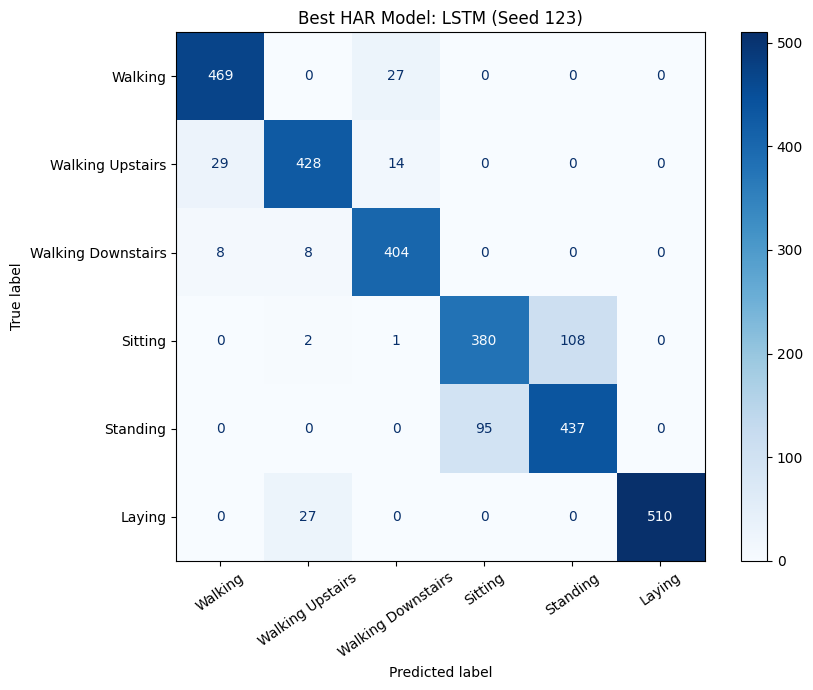

In [ ]:

# =====================================================
# P1.3: CONFUSION MATRIX OF BEST MODEL
# =====================================================

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model_name = best_validation_run["Model"]
best_seed = best_validation_run["Seed"]

best_predictions = best_validation_run["Test Predictions"]
best_actual = best_validation_run["Test Actual"]

print("Best model:", best_model_name)
print("Selected seed:", best_seed)
print(
    "Validation accuracy:",
    round(best_validation_run["Validation Accuracy"], 4)
)

class_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

best_cm = confusion_matrix(
    best_actual,
    best_predictions,
    labels=[0, 1, 2, 3, 4, 5]
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=best_cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=35,
    ax=ax
)

plt.title(
    f"Best HAR Model: {best_model_name} (Seed {best_seed})"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p13_best_model_confusion_matrix.png",
    dpi=300
)

plt.show()


In [ ]:

# =====================================================
# P1.3: VERIFICATION
# =====================================================

assert len(har_p13_runs) == 9

assert set(har_p13_df["Model"]) == {
    "RNN", "LSTM", "GRU"
}

assert set(har_p13_df["Seed"]) == {
    42, 123, 2026
}

assert np.isfinite(
    har_p13_df[
        [
            "Test Accuracy",
            "Macro F1",
            "Parameters",
            "Seconds per Epoch"
        ]
    ].values
).all()

print("P1.3 verification successful!")
print("Total runs:", len(har_p13_runs))
print("All three models trained on all three seeds.")


P1.3 verification successful!
Total runs: 9
All three models trained on all three seeds.


In [ ]:

# ==========================================
# P1.3: SAVE ALL NINE RUNS TO results.csv
# ==========================================

results_columns = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes"
]

p13_csv_rows = []

for run in har_p13_runs:
    p13_csv_rows.append({
        "problem": "P1.3_HAR",
        "model": run["Model"],
        "seed": run["Seed"],
        "seq_len": 128,
        "test_acc": run["Test Accuracy"],
        "macro_f1": run["Macro F1"],
        "test_mse": "",
        "params": run["Parameters"],
        "sec_per_epoch": run["Seconds per Epoch"],
        "val_loss_nats": "",
        "bits_per_char": "",
        "notes": "HAR classification; 20 epochs"
    })

new_p13_results = pd.DataFrame(
    p13_csv_rows,
    columns=results_columns
)

# Read existing results without deleting other experiments
existing_results = pd.read_csv(RESULTS_FILE)

# Remove earlier P1.3 rows to avoid duplicates
existing_results = existing_results[
    existing_results["problem"] != "P1.3_HAR"
]

# Append the latest nine runs
updated_results = pd.concat(
    [existing_results, new_p13_results],
    ignore_index=True
)

updated_results.to_csv(RESULTS_FILE, index=False)

# Verify
check_results = pd.read_csv(RESULTS_FILE)

assert len(
    check_results[
        check_results["problem"] == "P1.3_HAR"
    ]
) == 9

print("P1.3 results saved successfully!")
print(check_results[
    check_results["problem"] == "P1.3_HAR"
].to_string(index=False))


P1.3 results saved successfully!
 problem model  seed  seq_len  test_acc  macro_f1  test_mse  params  sec_per_epoch  val_loss_nats  bits_per_char                         notes
P1.3_HAR   RNN    42      128  0.777061  0.766301       NaN    5190       4.169078            NaN            NaN HAR classification; 20 epochs
P1.3_HAR  LSTM    42      128  0.893790  0.893566       NaN   19590       8.730124            NaN            NaN HAR classification; 20 epochs
P1.3_HAR   GRU    42      128  0.873770  0.871713       NaN   14790       9.946344            NaN            NaN HAR classification; 20 epochs
P1.3_HAR   RNN   123      128  0.739057  0.735862       NaN    5190       4.010468            NaN            NaN HAR classification; 20 epochs
P1.3_HAR  LSTM   123      128  0.891754  0.892693       NaN   19590       8.736371            NaN            NaN HAR classification; 20 epochs
P1.3_HAR   GRU   123      128  0.891076  0.890738       NaN   14790       9.548762            NaN            

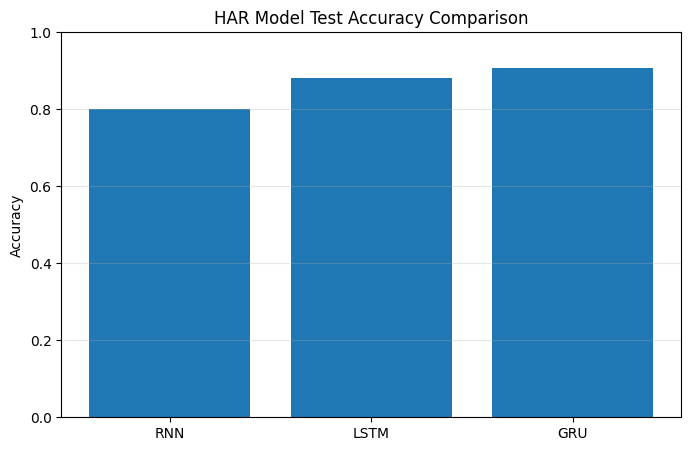

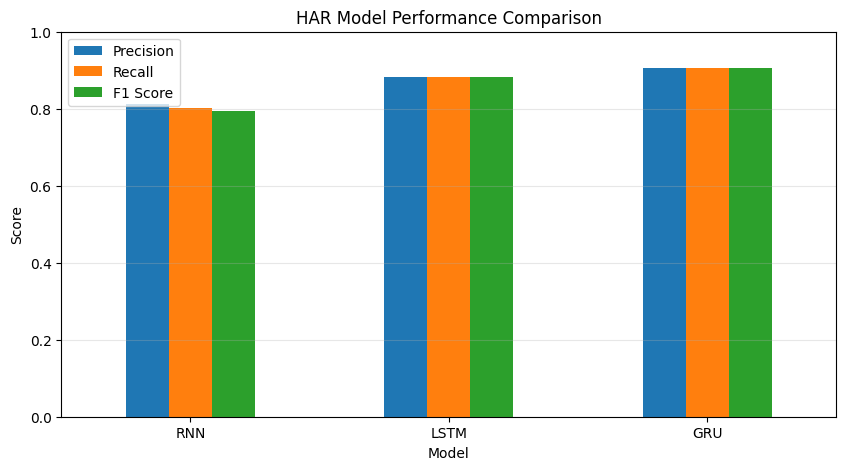

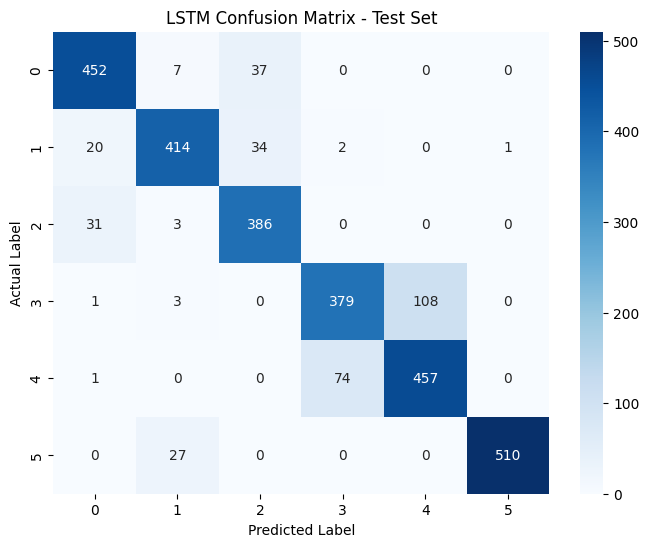

FINAL LSTM TEST CLASSIFICATION REPORT
                    precision    recall  f1-score   support

           Walking       0.90      0.91      0.90       496
  Walking Upstairs       0.91      0.88      0.90       471
Walking Downstairs       0.84      0.92      0.88       420
           Sitting       0.83      0.77      0.80       491
          Standing       0.81      0.86      0.83       532
            Laying       1.00      0.95      0.97       537

          accuracy                           0.88      2947
         macro avg       0.88      0.88      0.88      2947
      weighted avg       0.88      0.88      0.88      2947



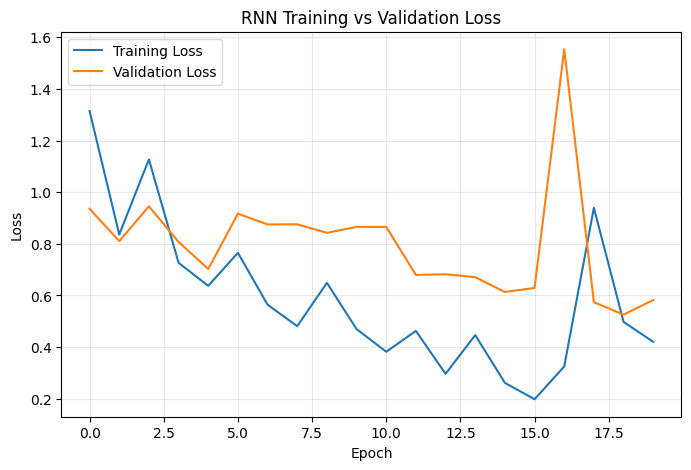

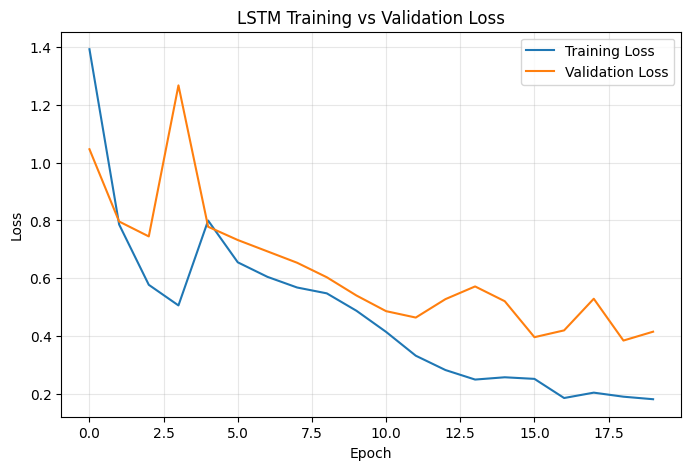

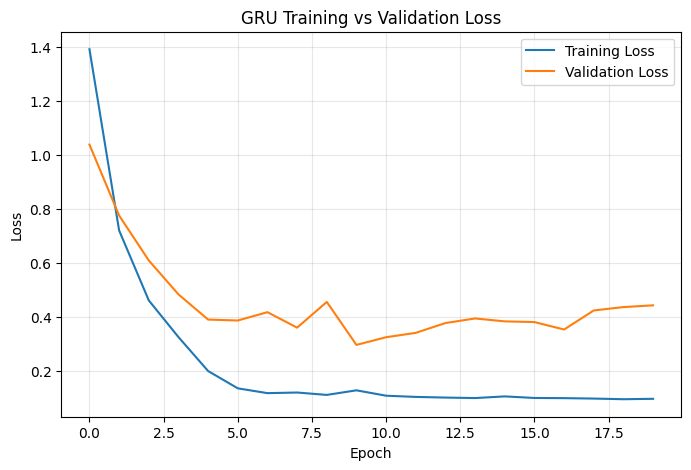

All training curves generated successfully!


FINAL BEST MODEL: ORIGINAL LSTM

Classification Report:

                    precision    recall  f1-score   support

           Walking     0.8950    0.9113    0.9031       496
  Walking Upstairs     0.9119    0.8790    0.8951       471
Walking Downstairs     0.8446    0.9190    0.8803       420
           Sitting     0.8330    0.7719    0.8013       491
          Standing     0.8088    0.8590    0.8332       532
            Laying     0.9980    0.9497    0.9733       537

          accuracy                         0.8816      2947
         macro avg     0.8819    0.8817    0.8810      2947
      weighted avg     0.8834    0.8816    0.8818      2947



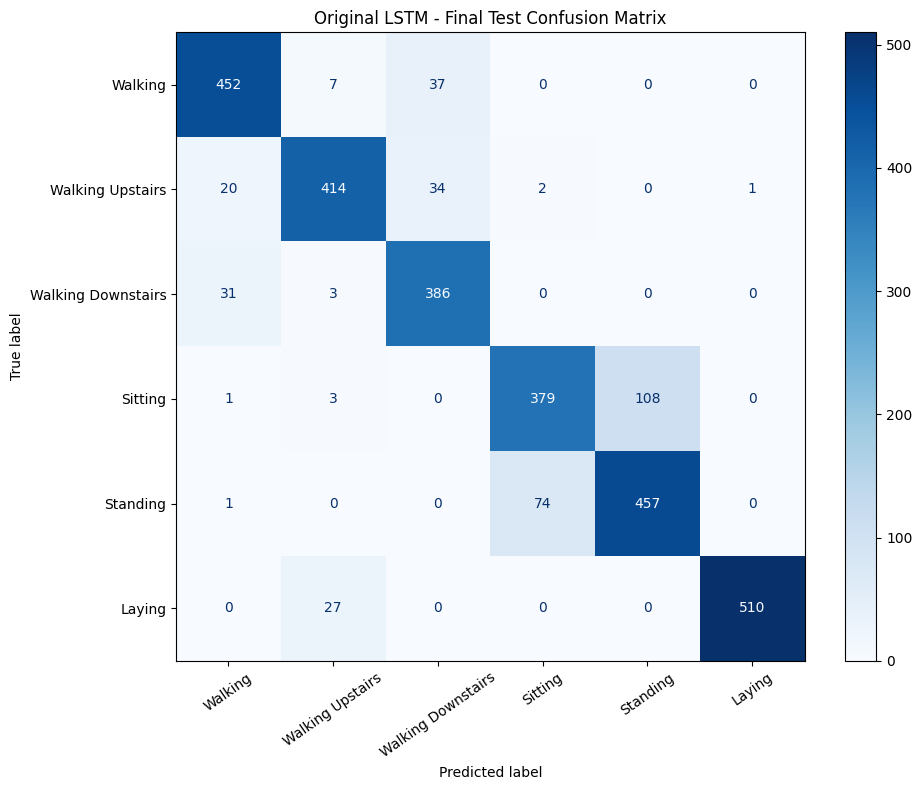


Final LSTM evaluation completed successfully!


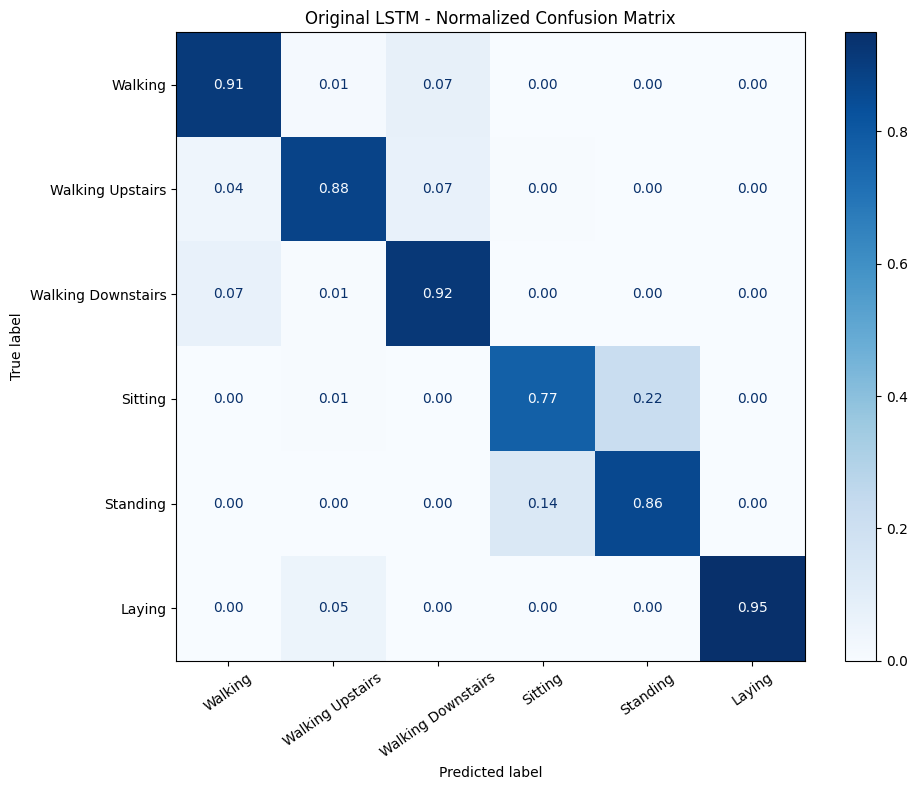

Normalized confusion matrix generated successfully!


In [ ]:

# ==========================================
# P1.4 - ADDING PROBLEM REGRESSION MODEL
# ==========================================

class AddingRegressor(nn.Module):
    def __init__(self, cell_type="LSTM", hidden_size=64):
        super().__init__()

        self.cell_type = cell_type.upper()
        self.hidden_size = hidden_size

        if self.cell_type == "RNN":
            self.recurrent = nn.RNN(
                input_size=2, hidden_size=hidden_size,
                batch_first=True
            )
        elif self.cell_type == "LSTM":
            self.recurrent = nn.LSTM(
                input_size=2, hidden_size=hidden_size,
                batch_first=True
            )
        elif self.cell_type == "GRU":
            self.recurrent = nn.GRU(
                input_size=2, hidden_size=hidden_size,
                batch_first=True
            )
        else:
            raise ValueError("Unsupported recurrent model")

        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence_output, _ = self.recurrent(x)
        last_hidden = sequence_output[:, -1, :]
        return self.output(last_hidden).squeeze(-1)


# Unit test
for name in ["RNN", "LSTM", "GRU"]:
    model = AddingRegressor(name, hidden_size=64).to(device)
    x = torch.randn(8, 100, 2, device=device)
    y = model(x)

    assert y.shape == (8,)
    assert torch.isfinite(y).all()

    print(name, "passed | parameters:",
          sum(p.numel() for p in model.parameters()))


RNN passed | parameters: 4417
LSTM passed | parameters: 17473
GRU passed | parameters: 13121


In [ ]:

def train_adding_model(
    model,
    train_data,
    val_data,
    test_data,
    seed,
    epochs=20,
    batch_size=64,
    learning_rate=1e-3,
    grad_clip_norm=1.0
):
    set_seed(seed)

    train_x, train_y = train_data
    val_x, val_y = val_data
    test_x, test_y = test_data

    train_loader = DataLoader(
        TensorDataset(
            torch.tensor(train_x, dtype=torch.float32),
            torch.tensor(train_y, dtype=torch.float32)
        ),
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        TensorDataset(
            torch.tensor(val_x, dtype=torch.float32),
            torch.tensor(val_y, dtype=torch.float32)
        ),
        batch_size=256,
        shuffle=False
    )

    test_loader = DataLoader(
        TensorDataset(
            torch.tensor(test_x, dtype=torch.float32),
            torch.tensor(test_y, dtype=torch.float32)
        ),
        batch_size=256,
        shuffle=False
    )

    model = model.to(device)

    criterion = nn.MSELoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_mse": [],
        "val_mse": [],
        "epoch_time": []
    }

    best_val_mse = float("inf")
    best_state = None

    for epoch in range(epochs):

        start = time.perf_counter()

        model.train()
        train_loss_sum = 0.0

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad(set_to_none=True)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            loss.backward()

            # torch.nn.utils.clip_grad_norm_(
            #     model.parameters(),
            #     max_norm=1.0
            # )
            if grad_clip_norm is not None:
               torch.nn.utils.clip_grad_norm_(
                  model.parameters(),
                   max_norm=grad_clip_norm
            )


            optimizer.step()

            train_loss_sum += loss.item() * inputs.size(0)

        train_mse = train_loss_sum / len(train_loader.dataset)

        model.eval()
        val_loss_sum = 0.0

        with torch.no_grad():
            for inputs, targets in val_loader:

                inputs = inputs.to(device)
                targets = targets.to(device)

                predictions = model(inputs)
                loss = criterion(predictions, targets)

                val_loss_sum += loss.item() * inputs.size(0)

        val_mse = val_loss_sum / len(val_loader.dataset)

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start

        history["train_mse"].append(train_mse)
        history["val_mse"].append(val_mse)
        history["epoch_time"].append(elapsed)

        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch+1:02d}/{epochs} | "
            f"Train MSE: {train_mse:.5f} | "
            f"Val MSE: {val_mse:.5f} | "
            f"Time: {elapsed:.2f}s"
        )

    model.load_state_dict(best_state)
    model.eval()

    test_loss_sum = 0.0

    with torch.no_grad():
        for inputs, targets in test_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            predictions = model(inputs)
            loss = criterion(predictions, targets)

            test_loss_sum += loss.item() * inputs.size(0)

    test_mse = test_loss_sum / len(test_loader.dataset)

    return model, history, test_mse


In [ ]:

# ==========================================
# P1.5(c): GRADIENT CLIPPING ABLATION
# VANILLA RNN | T=200
# ==========================================

ABLATION_T = 200
ABLATION_SEEDS = EXPERIMENT_SEEDS
ABLATION_EPOCHS = 20
ABLATION_HIDDEN_SIZE = 64

CLIPPING_CONFIGS = {
    "Clipping (norm=1.0)": 1.0,
    "No clipping": None
}

ablation_results = []
ablation_histories = {}

for seed_value in ABLATION_SEEDS:

    for config_name, clip_norm in CLIPPING_CONFIGS.items():

        print("\n" + "=" * 65)
        print(
            f"RNN | T={ABLATION_T} | Seed={seed_value} "
            f"| {config_name}"
        )
        print("=" * 65)

        # Reset seed before model initialization.
        # This gives both conditions the same initial weights.
        set_seed(seed_value)

        model = AddingRegressor(
            cell_type="RNN",
            hidden_size=ABLATION_HIDDEN_SIZE
        ).to(device)

        params = sum(
            p.numel()
            for p in model.parameters()
            if p.requires_grad
        )

        model, history, test_mse = train_adding_model(
            model=model,
            train_data=adding_datasets[ABLATION_T]["train"],
            val_data=adding_datasets[ABLATION_T]["validation"],
            test_data=adding_datasets[ABLATION_T]["test"],
            seed=seed_value,
            epochs=ABLATION_EPOCHS,
            batch_size=64,
            learning_rate=1e-3,
            grad_clip_norm=clip_norm
        )

        seconds_per_epoch = np.mean(history["epoch_time"])

        result = {
            "Model": "RNN",
            "Condition": config_name,
            "Seed": seed_value,
            "T": ABLATION_T,
            "Test MSE": test_mse,
            "Solved": test_mse < 0.05,
            "Parameters": params,
            "Seconds per Epoch": seconds_per_epoch
        }

        ablation_results.append(result)

        ablation_histories[(config_name, seed_value)] = history

        print(f"Test MSE: {test_mse:.6f}")
        print(f"Solved: {test_mse < 0.05}")
        print(f"Parameters: {params}")
        print(f"Seconds per epoch: {seconds_per_epoch:.2f}")

print("\nAll 6 ablation runs completed!")



RNN | T=200 | Seed=42 | Clipping (norm=1.0)
Epoch 01/20 | Train MSE: 0.19776 | Val MSE: 0.15990 | Time: 0.77s
Epoch 02/20 | Train MSE: 0.17048 | Val MSE: 0.16205 | Time: 0.77s
Epoch 03/20 | Train MSE: 0.16961 | Val MSE: 0.16230 | Time: 0.73s
Epoch 04/20 | Train MSE: 0.16919 | Val MSE: 0.15986 | Time: 0.57s
Epoch 05/20 | Train MSE: 0.17000 | Val MSE: 0.16467 | Time: 0.48s
Epoch 06/20 | Train MSE: 0.16949 | Val MSE: 0.16041 | Time: 0.48s
Epoch 07/20 | Train MSE: 0.16929 | Val MSE: 0.15959 | Time: 0.58s
Epoch 08/20 | Train MSE: 0.16930 | Val MSE: 0.16028 | Time: 0.59s
Epoch 09/20 | Train MSE: 0.16955 | Val MSE: 0.16144 | Time: 0.59s
Epoch 10/20 | Train MSE: 0.16905 | Val MSE: 0.15960 | Time: 0.61s
Epoch 11/20 | Train MSE: 0.16946 | Val MSE: 0.15987 | Time: 0.64s
Epoch 12/20 | Train MSE: 0.16875 | Val MSE: 0.16312 | Time: 0.47s
Epoch 13/20 | Train MSE: 0.16911 | Val MSE: 0.16005 | Time: 0.49s
Epoch 14/20 | Train MSE: 0.16960 | Val MSE: 0.15962 | Time: 0.47s
Epoch 15/20 | Train MSE: 0.1690

In [ ]:

# ==========================================
# P1.5(c): ABLATION SUMMARY
# ==========================================

ablation_df = pd.DataFrame(ablation_results)

ablation_summary = ablation_df.groupby(
    "Condition"
).agg(
    Mean_Test_MSE=("Test MSE", "mean"),
    Std_Test_MSE=("Test MSE", "std"),
    Solved_Runs=("Solved", "sum"),
    Parameters=("Parameters", "mean"),
    Seconds_Per_Epoch=("Seconds per Epoch", "mean")
).reset_index()

print("GRADIENT CLIPPING ABLATION RESULTS")
print("=" * 75)

print(ablation_summary.round(6).to_string(index=False))

print("\nIndividual seed results:")
print(ablation_df.round(6).to_string(index=False))


GRADIENT CLIPPING ABLATION RESULTS
          Condition  Mean_Test_MSE  Std_Test_MSE  Solved_Runs  Parameters  Seconds_Per_Epoch
Clipping (norm=1.0)       0.168308      0.000053            0      4417.0           0.526772
        No clipping       0.168284      0.000104            0      4417.0           0.458889

Individual seed results:
Model           Condition  Seed   T  Test MSE  Solved  Parameters  Seconds per Epoch
  RNN Clipping (norm=1.0)    42 200  0.168362   False        4417           0.556122
  RNN         No clipping    42 200  0.168184   False        4417           0.456958
  RNN Clipping (norm=1.0)   123 200  0.168304   False        4417           0.517849
  RNN         No clipping   123 200  0.168392   False        4417           0.458588
  RNN Clipping (norm=1.0)  2026 200  0.168256   False        4417           0.506346
  RNN         No clipping  2026 200  0.168275   False        4417           0.461122


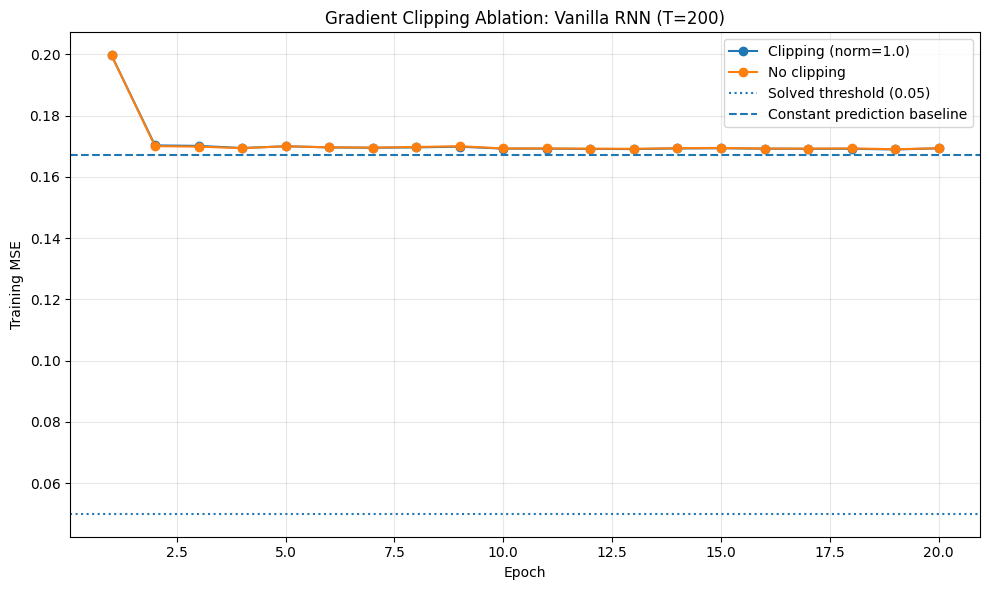

In [ ]:

# ==========================================
# P1.5(c): ABLATION LEARNING CURVES
# ==========================================

plt.figure(figsize=(10, 6))

for config_name in CLIPPING_CONFIGS:

    histories = [
        ablation_histories[(config_name, seed)]
        for seed in ABLATION_SEEDS
    ]

    train_curves = np.array([
        h["train_mse"] for h in histories
    ])

    mean_curve = train_curves.mean(axis=0)

    plt.plot(
        np.arange(1, ABLATION_EPOCHS + 1),
        mean_curve,
        marker="o",
        label=config_name
    )

plt.axhline(
    y=0.05,
    linestyle=":",
    label="Solved threshold (0.05)"
)

plt.axhline(
    y=0.167,
    linestyle="--",
    label="Constant prediction baseline"
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Gradient Clipping Ablation: Vanilla RNN (T=200)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p15_gradient_clipping_ablation.png",
    dpi=300
)

plt.show()


In [ ]:

# ==========================================
# P1.5(c): SAVE RESULTS AND VERIFY
# ==========================================

p15c_rows = []

for run in ablation_results:
    p15c_rows.append({
        "problem": "P1.5c_GradientClipping",
        "model": run["Model"],
        "seed": run["Seed"],
        "seq_len": run["T"],
        "test_acc": "",
        "macro_f1": "",
        "test_mse": run["Test MSE"],
        "params": run["Parameters"],
        "sec_per_epoch": run["Seconds per Epoch"],
        "val_loss_nats": "",
        "bits_per_char": "",
        "notes": (
            f"{run['Condition']}; "
            f"solved={run['Solved']}"
        )
    })

new_p15c = pd.DataFrame(p15c_rows)

existing_results = pd.read_csv(RESULTS_FILE)

existing_results = existing_results[
    existing_results["problem"] != "P1.5c_GradientClipping"
]

updated_results = pd.concat(
    [existing_results, new_p15c],
    ignore_index=True
)

updated_results.to_csv(RESULTS_FILE, index=False)

assert len(ablation_results) == 6
assert set(ablation_df["Seed"]) == {42, 123, 2026}
assert set(ablation_df["Condition"]) == {
    "Clipping (norm=1.0)",
    "No clipping"
}
assert np.isfinite(ablation_df["Test MSE"]).all()

print("P1.5(c) verification successful!")
print("Total runs:", len(ablation_results))
print("Results saved to:", RESULTS_FILE)


In [ ]:

# ==========================================
# P1.4 - SMOKE TEST (T=50, RNN)
# ==========================================

set_seed(42)

adding_test_model = AddingRegressor(
    cell_type="RNN",
    hidden_size=64
)

# Use small subsets for the smoke test
small_train = (
    adding_datasets[50]["train"][0][:256],
    adding_datasets[50]["train"][1][:256]
)

small_val = (
    adding_datasets[50]["validation"][0][:128],
    adding_datasets[50]["validation"][1][:128]
)

small_test = (
    adding_datasets[50]["test"][0][:128],
    adding_datasets[50]["test"][1][:128]
)

adding_test_model, adding_test_history, adding_test_mse = (
    train_adding_model(
        model=adding_test_model,
        train_data=small_train,
        val_data=small_val,
        test_data=small_test,
        seed=42,
        epochs=2,
        batch_size=64,
        learning_rate=1e-3
    )
)

# Verify smoke test
assert len(adding_test_history["train_mse"]) == 2
assert len(adding_test_history["val_mse"]) == 2
assert np.isfinite(adding_test_mse)
assert adding_test_mse >= 0

print("\nP1.4 smoke test passed!")
print(f"Test MSE: {adding_test_mse:.5f}")
print("Baseline MSE: approximately 0.167")


Epoch 01/2 | Train MSE: 0.91640 | Val MSE: 0.65529 | Time: 0.31s
Epoch 02/2 | Train MSE: 0.49594 | Val MSE: 0.24841 | Time: 0.02s

P1.4 smoke test passed!
Test MSE: 0.25336
Baseline MSE: approximately 0.167


In [ ]:

# ==========================================
# P1.4: FULL ADDING PROBLEM EXPERIMENT
# 4 LENGTHS x 3 MODELS x 3 SEEDS = 36 RUNS
# ==========================================

ADDING_LENGTHS = [50, 100, 200, 400]
ADDING_MODELS = ["RNN", "LSTM", "GRU"]

ADDING_EPOCHS = 20
ADDING_HIDDEN_SIZE = 64
ADDING_BATCH_SIZE = 64
ADDING_LR = 1e-3

adding_results = []
adding_histories = {}

for T in ADDING_LENGTHS:

    print("\n" + "=" * 65)
    print(f"ADDING PROBLEM: SEQUENCE LENGTH T={T}")
    print("=" * 65)

    for model_name in ADDING_MODELS:

        for seed_value in EXPERIMENT_SEEDS:

            print(f"\nTraining {model_name} | T={T} | Seed={seed_value}")

            set_seed(seed_value)

            model = AddingRegressor(
                cell_type=model_name,
                hidden_size=ADDING_HIDDEN_SIZE
            ).to(device)

            params = sum(
                p.numel() for p in model.parameters()
                if p.requires_grad
            )

            train_data = adding_datasets[T]["train"]
            val_data = adding_datasets[T]["validation"]
            test_data = adding_datasets[T]["test"]

            model, history, test_mse = train_adding_model(
                model=model,
                train_data=train_data,
                val_data=val_data,
                test_data=test_data,
                seed=seed_value,
                epochs=ADDING_EPOCHS,
                batch_size=ADDING_BATCH_SIZE,
                learning_rate=ADDING_LR
            )

            seconds_per_epoch = np.mean(history["epoch_time"])

            result = {
                "Model": model_name,
                "T": T,
                "Seed": seed_value,
                "Test MSE": test_mse,
                "Solved": test_mse < 0.05,
                "Parameters": params,
                "Seconds per Epoch": seconds_per_epoch
            }

            adding_results.append(result)

            # Retain learning curves for every run at T=200
            if T == 200:
                adding_histories[(model_name, seed_value)] = history

            print(f"Test MSE: {test_mse:.6f}")
            print(f"Solved: {test_mse < 0.05}")
            print(f"Parameters: {params}")
            print(f"Seconds per epoch: {seconds_per_epoch:.2f}")

print("\nAll 36 adding-problem runs completed!")



ADDING PROBLEM: SEQUENCE LENGTH T=50

Training RNN | T=50 | Seed=42
Epoch 01/20 | Train MSE: 0.19455 | Val MSE: 0.16815 | Time: 0.44s
Epoch 02/20 | Train MSE: 0.16811 | Val MSE: 0.16620 | Time: 0.42s
Epoch 03/20 | Train MSE: 0.16705 | Val MSE: 0.16833 | Time: 0.45s
Epoch 04/20 | Train MSE: 0.16628 | Val MSE: 0.16824 | Time: 0.43s
Epoch 05/20 | Train MSE: 0.16704 | Val MSE: 0.16593 | Time: 0.44s
Epoch 06/20 | Train MSE: 0.16691 | Val MSE: 0.16673 | Time: 0.43s
Epoch 07/20 | Train MSE: 0.16644 | Val MSE: 0.16644 | Time: 0.46s
Epoch 08/20 | Train MSE: 0.16587 | Val MSE: 0.17168 | Time: 0.44s
Epoch 09/20 | Train MSE: 0.16660 | Val MSE: 0.16593 | Time: 0.44s
Epoch 10/20 | Train MSE: 0.16592 | Val MSE: 0.16950 | Time: 0.44s
Epoch 11/20 | Train MSE: 0.16640 | Val MSE: 0.16576 | Time: 0.44s
Epoch 12/20 | Train MSE: 0.16560 | Val MSE: 0.16585 | Time: 0.52s
Epoch 13/20 | Train MSE: 0.16600 | Val MSE: 0.16785 | Time: 0.54s
Epoch 14/20 | Train MSE: 0.16507 | Val MSE: 0.16515 | Time: 0.56s
Epoch 1

In [ ]:

# ==========================================
# P1.4: ADDING PROBLEM RESULTS SUMMARY
# MEAN +/- STANDARD DEVIATION
# ==========================================

adding_df = pd.DataFrame(adding_results)

adding_summary = adding_df.groupby(
    ["Model", "T"]
).agg(
    Mean_Test_MSE=("Test MSE", "mean"),
    Std_Test_MSE=("Test MSE", "std"),
    Parameters=("Parameters", "mean"),
    Seconds_Per_Epoch=("Seconds per Epoch", "mean")
).reset_index()

print("ADDING PROBLEM: TEST MSE (MEAN +/- STD)")
print("=" * 75)

print(adding_summary.round(5).to_string(index=False))


ADDING PROBLEM: TEST MSE (MEAN +/- STD)
Model   T  Mean_Test_MSE  Std_Test_MSE  Parameters  Seconds_Per_Epoch
  GRU  50        0.00081       0.00023     13121.0            0.50047
  GRU 100        0.00119       0.00020     13121.0            0.50917
  GRU 200        0.00147       0.00050     13121.0            0.53252
  GRU 400        0.00512       0.00010     13121.0            0.55793
 LSTM  50        0.00571       0.00176     17473.0            0.54051
 LSTM 100        0.06757       0.08911     17473.0            0.53276
 LSTM 200        0.16828       0.00010     17473.0            0.53404
 LSTM 400        0.15356       0.00012     17473.0            0.57061
  RNN  50        0.11590       0.04942      4417.0            0.46685
  RNN 100        0.17018       0.00033      4417.0            0.48205
  RNN 200        0.16831       0.00005      4417.0            0.50858
  RNN 400        0.15405       0.00050      4417.0            0.51663


In [ ]:

# ==========================================
# P1.4: SOLVED RUNS TABLE
# ==========================================

solved_table = adding_df.groupby(
    ["Model", "T"]
).agg(
    Solved_Runs=("Solved", "sum"),
    Total_Runs=("Solved", "count")
).reset_index()

print("SOLVED RUNS (TEST MSE < 0.05)")
print("=" * 65)

print(solved_table.to_string(index=False))


SOLVED RUNS (TEST MSE < 0.05)
Model   T  Solved_Runs  Total_Runs
  GRU  50            3           3
  GRU 100            3           3
  GRU 200            3           3
  GRU 400            3           3
 LSTM  50            3           3
 LSTM 100            2           3
 LSTM 200            0           3
 LSTM 400            0           3
  RNN  50            0           3
  RNN 100            0           3
  RNN 200            0           3
  RNN 400            0           3


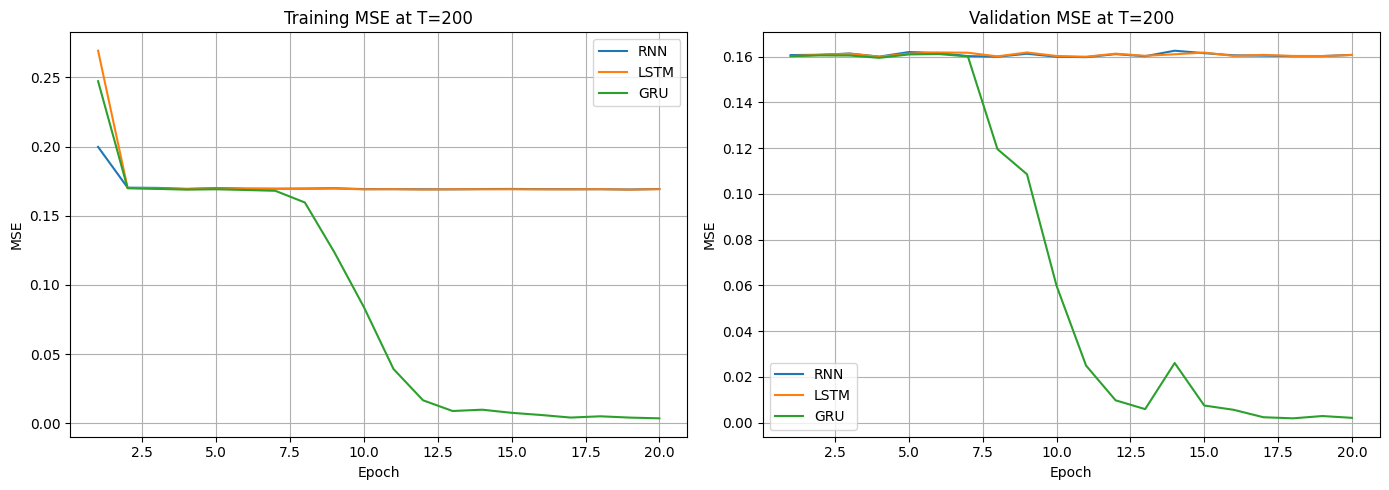

In [ ]:

# ==========================================
# P1.4: LEARNING CURVES AT T=200
# ==========================================

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for model_name in ADDING_MODELS:

    histories = [
        adding_histories[(model_name, seed)]
        for seed in EXPERIMENT_SEEDS
    ]

    train_curves = np.array([
        h["train_mse"] for h in histories
    ])

    val_curves = np.array([
        h["val_mse"] for h in histories
    ])

    epochs = np.arange(1, train_curves.shape[1] + 1)

    axes[0].plot(
        epochs,
        train_curves.mean(axis=0),
        label=model_name
    )

    axes[1].plot(
        epochs,
        val_curves.mean(axis=0),
        label=model_name
    )

axes[0].set_title("Training MSE at T=200")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation MSE at T=200")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p14_learning_curves_T200.png",
    dpi=300
)

plt.show()


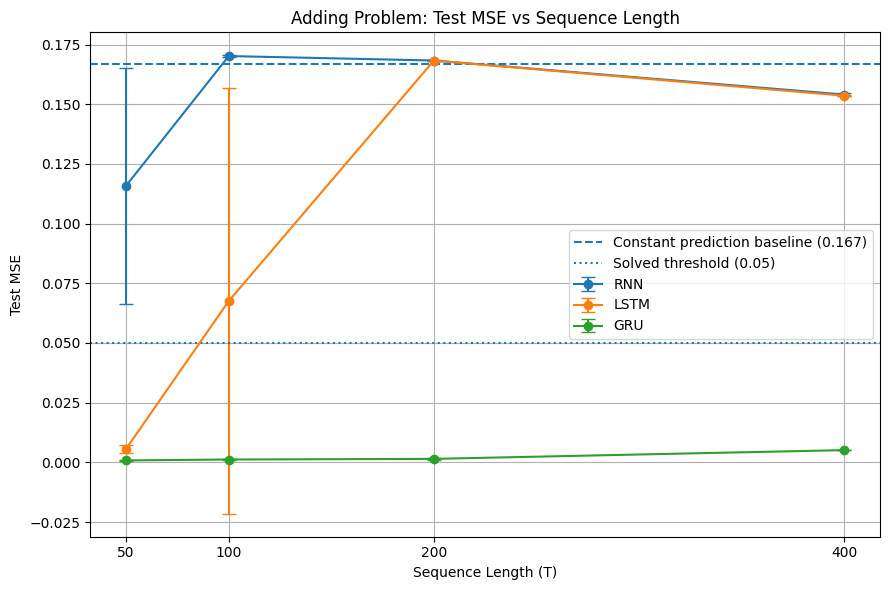

In [ ]:

# ==========================================
# P1.4: TEST MSE VS SEQUENCE LENGTH
# ==========================================

plt.figure(figsize=(9, 6))

for model_name in ADDING_MODELS:

    model_data = adding_summary[
        adding_summary["Model"] == model_name
    ].sort_values("T")

    plt.errorbar(
        model_data["T"],
        model_data["Mean_Test_MSE"],
        yerr=model_data["Std_Test_MSE"],
        marker="o",
        capsize=5,
        label=model_name
    )

plt.axhline(
    y=0.167,
    linestyle="--",
    label="Constant prediction baseline (0.167)"
)

plt.axhline(
    y=0.05,
    linestyle=":",
    label="Solved threshold (0.05)"
)

plt.xlabel("Sequence Length (T)")
plt.ylabel("Test MSE")
plt.title("Adding Problem: Test MSE vs Sequence Length")
plt.xticks(ADDING_LENGTHS)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p14_mse_vs_sequence_length.png",
    dpi=300
)

plt.show()


In [ ]:

# ==========================================
# P1.4: SAVE RESULTS TO CSV
# ==========================================

results_columns = [
    "problem",
    "model",
    "seed",
    "seq_len",
    "test_acc",
    "macro_f1",
    "test_mse",
    "params",
    "sec_per_epoch",
    "val_loss_nats",
    "bits_per_char",
    "notes"
]

p14_rows = []

for run in adding_results:

    p14_rows.append({
        "problem": "P1.4_Adding",
        "model": run["Model"],
        "seed": run["Seed"],
        "seq_len": run["T"],
        "test_acc": "",
        "macro_f1": "",
        "test_mse": run["Test MSE"],
        "params": run["Parameters"],
        "sec_per_epoch": run["Seconds per Epoch"],
        "val_loss_nats": "",
        "bits_per_char": "",
        "notes": (
            "Adding problem; "
            f"solved={run['Solved']}; "
            "20 epochs; gradient clipping norm=1.0"
        )
    })

new_p14_results = pd.DataFrame(
    p14_rows,
    columns=results_columns
)

existing_results = pd.read_csv(RESULTS_FILE)

# Avoid duplicate P1.4 rows if this cell is run again
existing_results = existing_results[
    existing_results["problem"] != "P1.4_Adding"
]

updated_results = pd.concat(
    [existing_results, new_p14_results],
    ignore_index=True
)

updated_results.to_csv(RESULTS_FILE, index=False)

check_results = pd.read_csv(RESULTS_FILE)

assert len(
    check_results[
        check_results["problem"] == "P1.4_Adding"
    ]
) == 36

print("P1.4 results saved successfully!")
print("Number of saved runs:", len(new_p14_results))


P1.4 results saved successfully!
Number of saved runs: 36


In [ ]:

# ==========================================
# P1.4: FINAL VERIFICATION
# ==========================================

assert len(adding_results) == 36
assert len(adding_df) == 36
assert set(adding_df["T"]) == {50, 100, 200, 400}
assert set(adding_df["Model"]) == {"RNN", "LSTM", "GRU"}
assert set(adding_df["Seed"]) == {42, 123, 2026}

assert np.isfinite(
    adding_df["Test MSE"].values
).all()

assert len(solved_table) == 12

assert all(
    (adding_df["Solved"] ==
     (adding_df["Test MSE"] < 0.05))
)

print("P1.4 verification successful!")
print("Total runs:", len(adding_results))
print("Sequence lengths:", ADDING_LENGTHS)
print("Models:", ADDING_MODELS)
print("Seeds:", EXPERIMENT_SEEDS)
print("Results saved in:", RESULTS_FILE)


P1.4 verification successful!
Total runs: 36
Sequence lengths: [50, 100, 200, 400]
Models: ['RNN', 'LSTM', 'GRU']
Seeds: [42, 123, 2026]
Results saved in: results.csv


Before-training gradient profile captured.
Epoch 01/20 | Train MSE: 0.19776 | Val MSE: 0.15990 | Time: 14.38s
Epoch 02/20 | Train MSE: 0.17048 | Val MSE: 0.16205 | Time: 10.79s
Epoch 03/20 | Train MSE: 0.16961 | Val MSE: 0.16230 | Time: 10.93s
Epoch 04/20 | Train MSE: 0.16919 | Val MSE: 0.15986 | Time: 10.89s
Epoch 05/20 | Train MSE: 0.16999 | Val MSE: 0.16466 | Time: 10.34s
Epoch 06/20 | Train MSE: 0.16949 | Val MSE: 0.16041 | Time: 10.67s
Epoch 07/20 | Train MSE: 0.16929 | Val MSE: 0.15959 | Time: 11.90s
Epoch 08/20 | Train MSE: 0.16930 | Val MSE: 0.16028 | Time: 11.17s
Epoch 09/20 | Train MSE: 0.16955 | Val MSE: 0.16144 | Time: 10.86s
Epoch 10/20 | Train MSE: 0.16905 | Val MSE: 0.15960 | Time: 10.89s
Epoch 11/20 | Train MSE: 0.16946 | Val MSE: 0.15987 | Time: 10.90s
Epoch 12/20 | Train MSE: 0.16875 | Val MSE: 0.16312 | Time: 10.45s
Epoch 13/20 | Train MSE: 0.16911 | Val MSE: 0.16005 | Time: 10.64s
Epoch 14/20 | Train MSE: 0.16960 | Val MSE: 0.15962 | Time: 11.08s
Epoch 15/20 | Train

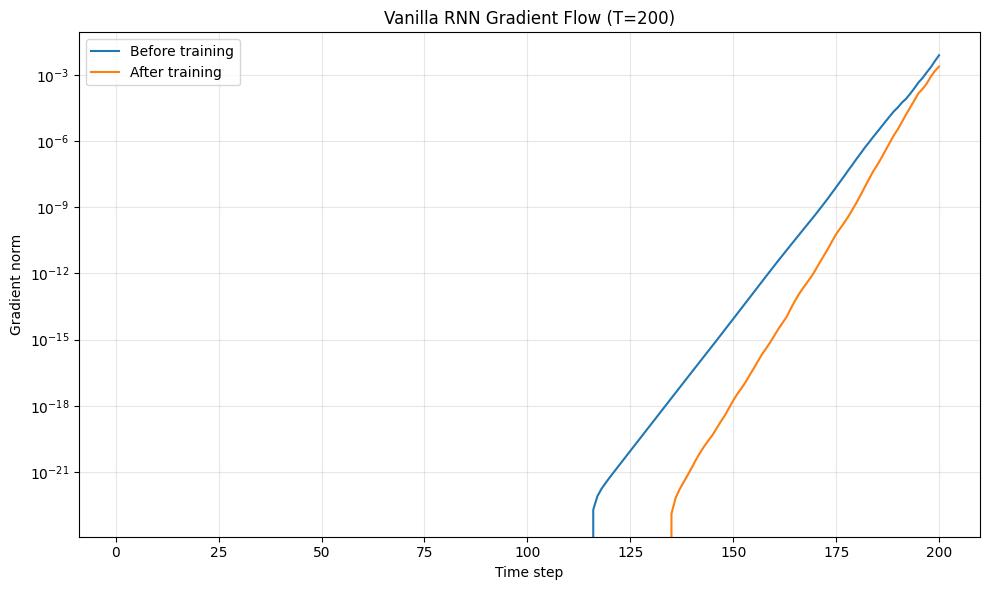

In [ ]:

# ==========================================
# P1.5(a): GRADIENT FLOW ANALYSIS
# VANILLA RNN, T=200
# ==========================================

class AddingRNNGradientModel(nn.Module):

    def __init__(self, hidden_size=64):
        super().__init__()

        self.rnn_cell = nn.RNNCell(
            input_size=2,
            hidden_size=hidden_size
        )

        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x, return_states=False):

        batch_size = x.size(0)

        hidden = torch.zeros(
            batch_size,
            self.rnn_cell.hidden_size,
            device=x.device
        )

        states = []

        for t in range(x.size(1)):

            hidden = self.rnn_cell(x[:, t, :], hidden)

            if return_states:
                hidden.retain_grad()
                states.append(hidden)

        prediction = self.output_layer(hidden).squeeze(-1)

        if return_states:
            return prediction, states

        return prediction


def get_gradient_profile(model, inputs, targets):

    model.train()
    model.zero_grad(set_to_none=True)

    inputs = torch.tensor(
        inputs, dtype=torch.float32, device=device
    )

    targets = torch.tensor(
        targets, dtype=torch.float32, device=device
    )

    predictions, states = model(
        inputs, return_states=True
    )

    loss = nn.MSELoss()(predictions, targets)
    loss.backward()

    gradient_norms = []

    for state in states:
        norm = state.grad.norm(p=2, dim=1).mean().item()
        gradient_norms.append(norm)

    return np.array(gradient_norms)


# Use a fixed batch for before/after comparison
gradient_train_x, gradient_train_y = adding_datasets[200]["train"]

gradient_x = gradient_train_x[:128]
gradient_y = gradient_train_y[:128]

# Initialize model
set_seed(42)

gradient_model = AddingRNNGradientModel(
    hidden_size=64
).to(device)

# Gradient profile BEFORE training
gradients_before = get_gradient_profile(
    gradient_model,
    gradient_x,
    gradient_y
)

print("Before-training gradient profile captured.")

# Train the same model on the full T=200 training set
gradient_model, gradient_history, gradient_test_mse = (
    train_adding_model(
        model=gradient_model,
        train_data=adding_datasets[200]["train"],
        val_data=adding_datasets[200]["validation"],
        test_data=adding_datasets[200]["test"],
        seed=42,
        epochs=20,
        batch_size=64,
        learning_rate=1e-3
    )
)

# Gradient profile AFTER training
gradients_after = get_gradient_profile(
    gradient_model,
    gradient_x,
    gradient_y
)

print("After-training gradient profile captured.")
print(f"Test MSE: {gradient_test_mse:.6f}")

# Plot gradient norms
timesteps = np.arange(1, 201)

plt.figure(figsize=(10, 6))

plt.plot(
    timesteps,
    gradients_before,
    label="Before training"
)

plt.plot(
    timesteps,
    gradients_after,
    label="After training"
)

plt.xlabel("Time step")
plt.ylabel("Gradient norm")
plt.title("Vanilla RNN Gradient Flow (T=200)")
plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p15_gradient_flow_T200.png",
    dpi=300
)

plt.show()


In [ ]:

# ==========================================
# P1.5(b): HIDDEN-SIZE SWEEP
# LSTM AND GRU | T=200
# ==========================================

HIDDEN_SIZES = [16, 32, 64, 128]
SWEEP_MODELS = ["LSTM", "GRU"]
SWEEP_T = 200

hidden_sweep_results = []

for model_name in SWEEP_MODELS:

    for hidden_size in HIDDEN_SIZES:

        for seed_value in EXPERIMENT_SEEDS:

            print("\n" + "=" * 65)
            print(
                f"Model={model_name} | Hidden={hidden_size} "
                f"| T={SWEEP_T} | Seed={seed_value}"
            )
            print("=" * 65)

            # Seed before model initialization
            set_seed(seed_value)

            model = AddingRegressor(
                cell_type=model_name,
                hidden_size=hidden_size
            ).to(device)

            params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            model, history, test_mse = train_adding_model(
                model=model,
                train_data=adding_datasets[SWEEP_T]["train"],
                val_data=adding_datasets[SWEEP_T]["validation"],
                test_data=adding_datasets[SWEEP_T]["test"],
                seed=seed_value,
                epochs=20,
                batch_size=64,
                learning_rate=1e-3
            )

            seconds_per_epoch = np.mean(history["epoch_time"])

            result = {
                "Model": model_name,
                "Hidden Size": hidden_size,
                "T": SWEEP_T,
                "Seed": seed_value,
                "Test MSE": test_mse,
                "Solved": test_mse < 0.05,
                "Parameters": params,
                "Seconds per Epoch": seconds_per_epoch
            }

            hidden_sweep_results.append(result)

            print(f"Test MSE: {test_mse:.6f}")
            print(f"Solved: {test_mse < 0.05}")
            print(f"Parameters: {params}")
            print(f"Seconds per epoch: {seconds_per_epoch:.2f}")

print("\nAll 24 hidden-size experiments completed!")



Model=LSTM | Hidden=16 | T=200 | Seed=42
Epoch 01/20 | Train MSE: 0.64532 | Val MSE: 0.16015 | Time: 1.07s
Epoch 02/20 | Train MSE: 0.16871 | Val MSE: 0.16011 | Time: 1.02s
Epoch 03/20 | Train MSE: 0.16861 | Val MSE: 0.16099 | Time: 1.23s
Epoch 04/20 | Train MSE: 0.16891 | Val MSE: 0.16095 | Time: 1.04s
Epoch 05/20 | Train MSE: 0.16906 | Val MSE: 0.15993 | Time: 0.86s
Epoch 06/20 | Train MSE: 0.16876 | Val MSE: 0.16069 | Time: 0.88s
Epoch 07/20 | Train MSE: 0.16879 | Val MSE: 0.15988 | Time: 0.86s
Epoch 08/20 | Train MSE: 0.16874 | Val MSE: 0.15985 | Time: 0.70s
Epoch 09/20 | Train MSE: 0.16892 | Val MSE: 0.16001 | Time: 0.90s
Epoch 10/20 | Train MSE: 0.16871 | Val MSE: 0.15998 | Time: 1.21s
Epoch 11/20 | Train MSE: 0.16874 | Val MSE: 0.15993 | Time: 1.15s
Epoch 12/20 | Train MSE: 0.16849 | Val MSE: 0.16143 | Time: 1.09s
Epoch 13/20 | Train MSE: 0.16901 | Val MSE: 0.15992 | Time: 0.82s
Epoch 14/20 | Train MSE: 0.16881 | Val MSE: 0.16005 | Time: 0.96s
Epoch 15/20 | Train MSE: 0.16878 |

In [ ]:

# ==========================================
# P1.5(b): HIDDEN-SIZE SUMMARY
# ==========================================

hidden_sweep_df = pd.DataFrame(hidden_sweep_results)

hidden_sweep_summary = hidden_sweep_df.groupby(
    ["Model", "Hidden Size"]
).agg(
    Mean_Test_MSE=("Test MSE", "mean"),
    Std_Test_MSE=("Test MSE", "std"),
    Parameters=("Parameters", "mean"),
    Seconds_Per_Epoch=("Seconds per Epoch", "mean"),
    Solved_Runs=("Solved", "sum")
).reset_index()

print("HIDDEN-SIZE SWEEP RESULTS")
print("=" * 75)

print(
    hidden_sweep_summary.round(5).to_string(index=False)
)


HIDDEN-SIZE SWEEP RESULTS
Model  Hidden Size  Mean_Test_MSE  Std_Test_MSE  Parameters  Seconds_Per_Epoch  Solved_Runs
  GRU           16        0.00430       0.00051       977.0            0.53996            3
  GRU           32        0.00227       0.00082      3489.0            0.52675            3
  GRU           64        0.00147       0.00050     13121.0            0.53919            3
  GRU          128        0.00060       0.00022     50817.0            0.61570            3
 LSTM           16        0.16853       0.00004      1297.0            0.84588            0
 LSTM           32        0.16829       0.00007      4641.0            0.55261            0
 LSTM           64        0.16828       0.00010     17473.0            0.58051            0
 LSTM          128        0.16854       0.00024     67713.0            0.94542            0


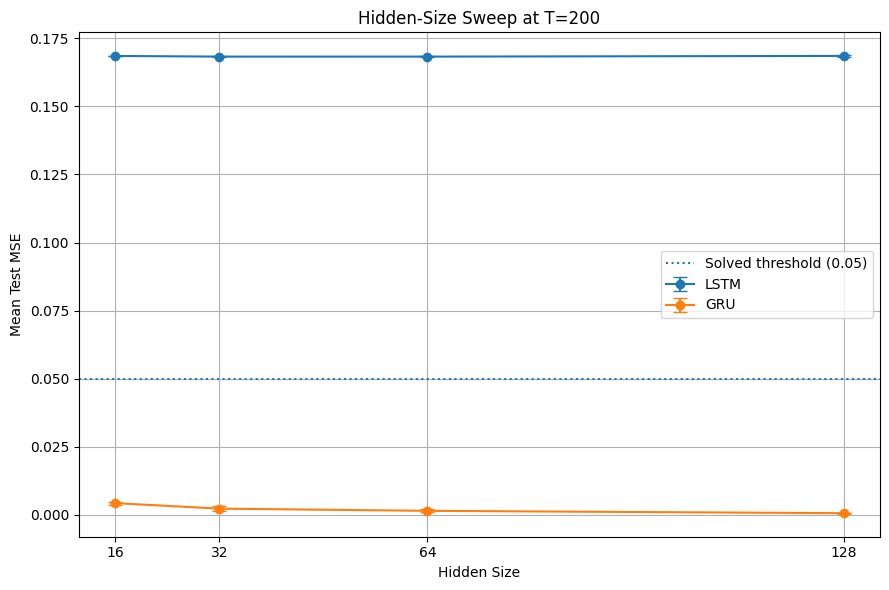

In [ ]:

# ==========================================
# P1.5(b): HIDDEN SIZE VS TEST MSE
# ==========================================

plt.figure(figsize=(9, 6))

for model_name in SWEEP_MODELS:

    model_data = hidden_sweep_summary[
        hidden_sweep_summary["Model"] == model_name
    ].sort_values("Hidden Size")

    plt.errorbar(
        model_data["Hidden Size"],
        model_data["Mean_Test_MSE"],
        yerr=model_data["Std_Test_MSE"],
        marker="o",
        capsize=5,
        label=model_name
    )

plt.axhline(
    y=0.05,
    linestyle=":",
    label="Solved threshold (0.05)"
)

plt.xlabel("Hidden Size")
plt.ylabel("Mean Test MSE")
plt.title("Hidden-Size Sweep at T=200")
plt.xticks(HIDDEN_SIZES)
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p15_hidden_size_sweep_T200.png",
    dpi=300
)

plt.show()


In [ ]:

# ==========================================
# P1.5(b): VERIFICATION
# ==========================================

assert len(hidden_sweep_results) == 24

assert set(hidden_sweep_df["Model"]) == {"LSTM", "GRU"}
assert set(hidden_sweep_df["Hidden Size"]) == {16, 32, 64, 128}
assert set(hidden_sweep_df["Seed"]) == {42, 123, 2026}

assert np.isfinite(hidden_sweep_df["Test MSE"]).all()

print("P1.5(b) verification successful!")
print("Total runs:", len(hidden_sweep_results))


P1.5(b) verification successful!
Total runs: 24


In [ ]:

# ==========================================
# P1.5(b): SAVE HIDDEN-SIZE RESULTS
# ==========================================

p15b_rows = []

for run in hidden_sweep_results:
    p15b_rows.append({
        "problem": "P1.5b_HiddenSweep",
        "model": run["Model"],
        "seed": run["Seed"],
        "seq_len": run["T"],
        "test_acc": "",
        "macro_f1": "",
        "test_mse": run["Test MSE"],
        "params": run["Parameters"],
        "sec_per_epoch": run["Seconds per Epoch"],
        "val_loss_nats": "",
        "bits_per_char": "",
        "notes": (
            f"Hidden size={run['Hidden Size']}; "
            f"solved={run['Solved']}"
        )
    })

new_p15b = pd.DataFrame(p15b_rows)

existing_results = pd.read_csv(RESULTS_FILE)

existing_results = existing_results[
    existing_results["problem"] != "P1.5b_HiddenSweep"
]

updated_results = pd.concat(
    [existing_results, new_p15b],
    ignore_index=True
)

updated_results.to_csv(RESULTS_FILE, index=False)

assert len(new_p15b) == 24

print("P1.5(b) results saved!")
print("Saved runs:", len(new_p15b))


P1.5(b) results saved!
Saved runs: 24


In [1]:
# from pathlib import Path

# # Create assignment folders using relative paths
# BASE_DIR = Path("DNN_Assignment")
# FIGURES_DIR = BASE_DIR / "figures"

# BASE_DIR.mkdir(parents=True, exist_ok=True)
# FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# RESULTS_FILE = BASE_DIR / "results.csv"

# print("Assignment folder:", BASE_DIR)
# print("Results will be saved to:", RESULTS_FILE)

Assignment folder: DNN_Assignment
Results will be saved to: DNN_Assignment/results.csv


In [4]:
# from google.colab import files
# uploaded = files.upload()

Saving recovered_results.csv to recovered_results.csv


In [5]:
# import shutil

# shutil.copy(
#     "recovered_results.csv",
#     RESULTS_FILE
# )

# print("Saved:", RESULTS_FILE.exists())

Saved: True


In [6]:
import pandas as pd

df = pd.read_csv(RESULTS_FILE)

print(df.shape)
print(df["problem"].value_counts())

(76, 12)
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         1
Name: count, dtype: int64


In [7]:
import os
import pandas as pd

# Use the path defined in the setup cell
print("File exists:", RESULTS_FILE.exists())

if RESULTS_FILE.exists():
    df = pd.read_csv(RESULTS_FILE)
    print("Rows and columns:", df.shape)
    print(df["problem"].value_counts())
else:
    print("Results file not found:", RESULTS_FILE)

File exists: True
Rows and columns: (76, 12)
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         1
Name: count, dtype: int64


In [ ]:
# print("Number of HAR experiments:", len(har_experiments))

# for seed_value, exp in har_experiments.items():

#     print(f"\nExperiment for seed: {seed_value}")
#     print("Keys:", exp.keys())

#     for key, value in exp.items():

#         if isinstance(value, np.ndarray):
#             print(key, value.shape)

Number of HAR experiments: 3

Experiment for seed: 42
Keys: dict_keys(['seed', 'validation_subjects', 'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'mean', 'std'])
validation_subjects (4,)
X_train (5952, 128, 9)
y_train (5952,)
X_val (1400, 128, 9)
y_val (1400,)
X_test (2947, 128, 9)
y_test (2947,)
mean (9,)
std (9,)

Experiment for seed: 123
Keys: dict_keys(['seed', 'validation_subjects', 'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'mean', 'std'])
validation_subjects (4,)
X_train (5896, 128, 9)
y_train (5896,)
X_val (1456, 128, 9)
y_val (1456,)
X_test (2947, 128, 9)
y_test (2947,)
mean (9,)
std (9,)

Experiment for seed: 2026
Keys: dict_keys(['seed', 'validation_subjects', 'X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test', 'mean', 'std'])
validation_subjects (4,)
X_train (5950, 128, 9)
y_train (5950,)
X_val (1402, 128, 9)
y_val (1402,)
X_test (2947, 128, 9)
y_test (2947,)
mean (9,)
std (9,)


In [ ]:
# ==========================================
# TASK 3: HAR CLASSIFICATION
# 3 MODELS x 3 SEEDS = 9 EXPERIMENTS
# ==========================================

from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import torch
import numpy as np
import time

MODEL_TYPES = ["RNN", "LSTM", "GRU"]

har_results = []
har_trained_models = {}
har_histories = {}

for seed_value, exp in har_experiments.items():

    print("\n" + "=" * 65)
    print(f"HAR EXPERIMENT | SEED = {seed_value}")
    print("=" * 65)

    for model_type in MODEL_TYPES:

        print(f"\nTraining {model_type} | Seed={seed_value}")

        # Set seed before model initialization
        set_seed(seed_value)

        model = HARSequenceClassifier(
            cell_type=model_type,
            input_size=9,
            hidden_size=64,
            num_classes=6,
            dropout=0.3
        ).to(device)

        start_time = time.time()

        model, history = train_har_model(
            model=model,
            train_x=exp["X_train"],
            train_y=exp["y_train"],
            val_x=exp["X_val"],
            val_y=exp["y_val"],
            seed=seed_value,
            epochs=20,
            batch_size=64,
            learning_rate=0.001,
            patience=20
        )

        # Evaluate on test data
        model.eval()

        test_tensor = torch.tensor(
            exp["X_test"],
            dtype=torch.float32
        )

        test_loader = DataLoader(
            TensorDataset(test_tensor),
            batch_size=64,
            shuffle=False
        )

        predictions = []

        with torch.no_grad():
            for (batch_x,) in test_loader:
                batch_x = batch_x.to(device)
                outputs = model(batch_x)
                predictions.extend(
                    outputs.argmax(dim=1).cpu().numpy()
                )

        y_pred = np.array(predictions)
        y_true = exp["y_test"]

        accuracy = accuracy_score(y_true, y_pred)
        macro_f1 = f1_score(
            y_true,
            y_pred,
            average="macro"
        )

        elapsed = time.time() - start_time

        har_trained_models[(seed_value, model_type)] = model
        har_histories[(seed_value, model_type)] = history

        har_results.append({
            "Seed": seed_value,
            "Model": model_type,
            "Test Accuracy": accuracy,
            "Macro F1": macro_f1,
            "Best Val Loss": min(history["val_loss"]),
            "Epochs": len(history["train_loss"]),
            "Time (seconds)": elapsed
        })

        print(f"Test Accuracy: {accuracy:.4f}")
        print(f"Macro F1: {macro_f1:.4f}")
        print(f"Total time: {elapsed:.2f} seconds")


# Display all nine experiment results
har_results_df = pd.DataFrame(har_results)

print("\nHAR CLASSIFICATION RESULTS")
print("=" * 75)

print(
    har_results_df.round(4).to_string(index=False)
)

# Save separately; do not overwrite the existing results.csv
har_results_df.to_csv(
    BASE_DIR / "har_model_results.csv",
    index=False
)

print("\nAll 9 HAR experiments completed!")


HAR EXPERIMENT | SEED = 42

Training RNN | Seed=42
Epoch 01/20 | Train Loss: 1.2064 | Val Loss: 0.9236 | Time: 2.47s
Epoch 02/20 | Train Loss: 0.8246 | Val Loss: 0.7049 | Time: 3.28s
Epoch 03/20 | Train Loss: 0.6670 | Val Loss: 0.7364 | Time: 3.29s
Epoch 04/20 | Train Loss: 0.6169 | Val Loss: 0.7656 | Time: 2.67s
Epoch 05/20 | Train Loss: 0.5718 | Val Loss: 0.8288 | Time: 2.55s
Epoch 06/20 | Train Loss: 0.6289 | Val Loss: 0.7007 | Time: 2.49s
Epoch 07/20 | Train Loss: 0.4981 | Val Loss: 0.6088 | Time: 3.20s
Epoch 08/20 | Train Loss: 0.4368 | Val Loss: 0.5906 | Time: 3.40s
Epoch 09/20 | Train Loss: 0.4374 | Val Loss: 1.9154 | Time: 2.50s
Epoch 10/20 | Train Loss: 1.3132 | Val Loss: 0.9624 | Time: 2.87s
Epoch 11/20 | Train Loss: 0.6873 | Val Loss: 0.7691 | Time: 2.59s
Epoch 12/20 | Train Loss: 0.5500 | Val Loss: 0.7249 | Time: 3.61s
Epoch 13/20 | Train Loss: 0.5080 | Val Loss: 0.7094 | Time: 3.33s
Epoch 14/20 | Train Loss: 0.4502 | Val Loss: 0.6429 | Time: 2.54s
Epoch 15/20 | Train Loss

HAR CLASSIFICATION SUMMARY
Model  Mean_Accuracy  Std_Accuracy  Mean_Macro_F1  Std_Macro_F1  Parameters  Seconds_Per_Epoch
  GRU         0.8879        0.0078         0.8881        0.0082     14790.0             7.7516
 LSTM         0.8800        0.0080         0.8802        0.0085     19590.0             8.1797
  RNN         0.8043        0.0240         0.7978        0.0295      5190.0             2.9303


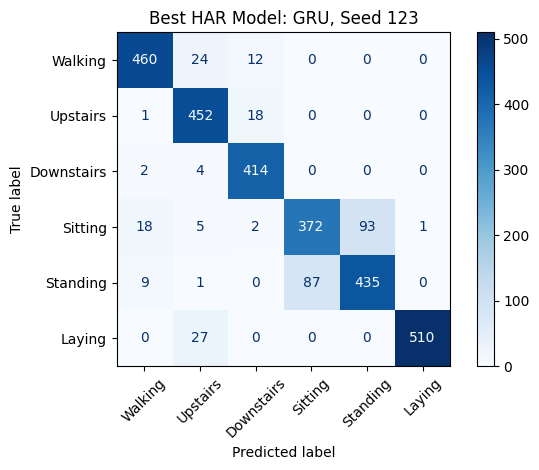


Gradient analysis: RNN
Epoch 01/20 | Train MSE: 0.19133 | Val MSE: 0.16227 | Time: 4.81s
Epoch 02/20 | Train MSE: 0.16855 | Val MSE: 0.16439 | Time: 3.35s
Epoch 03/20 | Train MSE: 0.16891 | Val MSE: 0.16065 | Time: 3.32s
Epoch 04/20 | Train MSE: 0.16847 | Val MSE: 0.16049 | Time: 3.22s
Epoch 05/20 | Train MSE: 0.16862 | Val MSE: 0.16068 | Time: 4.67s
Epoch 06/20 | Train MSE: 0.16798 | Val MSE: 0.16474 | Time: 3.62s
Epoch 07/20 | Train MSE: 0.16882 | Val MSE: 0.16113 | Time: 3.26s
Epoch 08/20 | Train MSE: 0.16739 | Val MSE: 0.16280 | Time: 3.26s
Epoch 09/20 | Train MSE: 0.16744 | Val MSE: 0.16019 | Time: 4.60s
Epoch 10/20 | Train MSE: 0.16713 | Val MSE: 0.16030 | Time: 3.80s
Epoch 11/20 | Train MSE: 0.16772 | Val MSE: 0.15978 | Time: 3.22s
Epoch 12/20 | Train MSE: 0.16675 | Val MSE: 0.15969 | Time: 3.21s
Epoch 13/20 | Train MSE: 0.16563 | Val MSE: 0.15988 | Time: 4.68s
Epoch 14/20 | Train MSE: 0.17395 | Val MSE: 0.16169 | Time: 3.55s
Epoch 15/20 | Train MSE: 0.17303 | Val MSE: 0.16069 

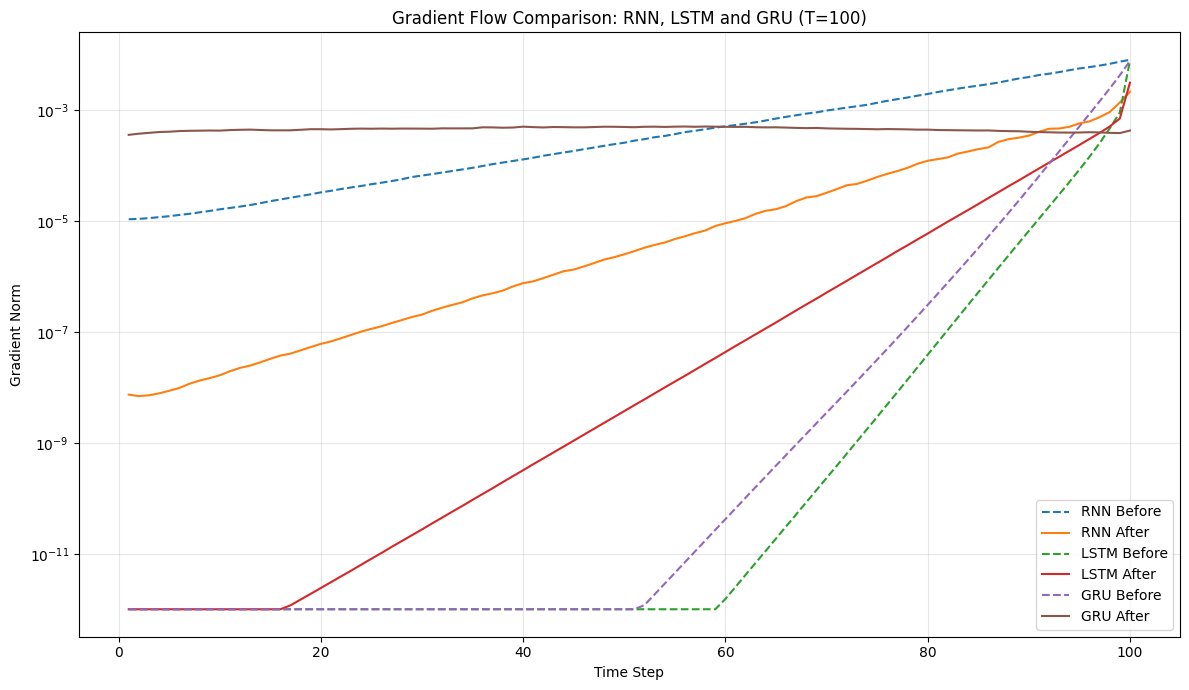


P1.5(a) gradient-flow experiment completed!


In [ ]:

# ==========================================
# P1.5(a): GRADIENT FLOW ANALYSIS
# RNN, LSTM AND GRU | T=100
# BEFORE AND AFTER TRAINING
# ==========================================

class AddingGradientModel(nn.Module):

    def __init__(self, cell_type, hidden_size=64):
        super().__init__()

        self.cell_type = cell_type
        self.hidden_size = hidden_size

        if cell_type == "RNN":
            self.cell = MyRNNCell(2, hidden_size)

        elif cell_type == "LSTM":
            self.cell = MyLSTMCell(2, hidden_size)

        elif cell_type == "GRU":
            self.cell = MyGRUCell(2, hidden_size)

        else:
            raise ValueError("Unsupported cell type")

        self.output_layer = nn.Linear(hidden_size, 1)

    def forward(self, x, return_states=False):

        batch_size = x.size(0)

        hidden = torch.zeros(
            batch_size,
            self.hidden_size,
            device=x.device
        )

        if self.cell_type == "LSTM":
            cell = torch.zeros_like(hidden)

        states = []

        for t in range(x.size(1)):

            current_input = x[:, t, :]

            if self.cell_type == "LSTM":
                hidden, cell = self.cell(
                    current_input,
                    (hidden, cell)
                )
            else:
                hidden = self.cell(current_input, hidden)

            if return_states:
                hidden.retain_grad()
                states.append(hidden)

        prediction = self.output_layer(hidden).squeeze(-1)

        if return_states:
            return prediction, states

        return prediction


def get_gradient_profile(model, x, y):

    model.eval()
    model.zero_grad(set_to_none=True)

    inputs = torch.tensor(
        x, dtype=torch.float32, device=device
    )

    targets = torch.tensor(
        y, dtype=torch.float32, device=device
    )

    predictions, states = model(
        inputs, return_states=True
    )

    loss = nn.MSELoss()(predictions, targets)
    loss.backward()

    gradient_norms = []

    for state in states:
        norm = state.grad.norm(p=2, dim=1).mean().item()
        gradient_norms.append(norm)

    return np.array(gradient_norms)


# Fixed T=100 batch for fair comparison
gradient_train_x, gradient_train_y = adding_datasets[100]["train"]

gradient_x = gradient_train_x[:128]
gradient_y = gradient_train_y[:128]

gradient_results = {}

for model_name in ["RNN", "LSTM", "GRU"]:

    print("\n" + "=" * 55)
    print("Gradient analysis:", model_name)
    print("=" * 55)

    # Set seed before model initialization
    set_seed(42)

    model = AddingGradientModel(
        cell_type=model_name,
        hidden_size=64
    ).to(device)

    # Gradients before training
    before = get_gradient_profile(
        model, gradient_x, gradient_y
    )

    # Train the same model
    model, history, test_mse = train_adding_model(
        model=model,
        train_data=adding_datasets[100]["train"],
        val_data=adding_datasets[100]["validation"],
        test_data=adding_datasets[100]["test"],
        seed=42,
        epochs=20,
        batch_size=64,
        learning_rate=1e-3
    )

    # Gradients after training
    after = get_gradient_profile(
        model, gradient_x, gradient_y
    )

    gradient_results[model_name] = {
        "before": before,
        "after": after,
        "test_mse": test_mse,
        "history": history
    }

    print("Test MSE:", round(test_mse, 6))
    print("Before gradient shape:", before.shape)
    print("After gradient shape:", after.shape)


# Plot all three models
timesteps = np.arange(1, 101)

plt.figure(figsize=(12, 7))

for model_name in ["RNN", "LSTM", "GRU"]:

    plt.plot(
        timesteps,
        np.maximum(
            gradient_results[model_name]["before"], 1e-12
        ),
        linestyle="--",
        label=f"{model_name} Before"
    )

    plt.plot(
        timesteps,
        np.maximum(
            gradient_results[model_name]["after"], 1e-12
        ),
        label=f"{model_name} After"
    )

plt.yscale("log")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Flow Comparison: RNN, LSTM and GRU (T=100)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p15a_gradient_flow_T100.png",
    dpi=300
)

plt.show()

print("\nP1.5(a) gradient-flow experiment completed!")


In [ ]:

import os
import shutil
import pandas as pd
import numpy as np

# 1. Check that the gradient experiment results exist
assert "gradient_results" in globals()
assert all(m in gradient_results for m in ["RNN", "LSTM", "GRU"])

# 2. Read the existing CSV
df_old = pd.read_csv(RESULTS_FILE)

# 3. Prepare the three T=100 records
new_rows = []

for model_name in ["RNN", "LSTM", "GRU"]:

    result = gradient_results[model_name]

    # Count model parameters
    temp_model = AddingGradientModel(
        cell_type=model_name,
        hidden_size=64
    )

    params = sum(
        p.numel() for p in temp_model.parameters()
        if p.requires_grad
    )

    seconds_per_epoch = np.mean(
        result["history"]["epoch_time"]
    )

    new_rows.append({
        "problem": "P1.5a_GradientFlow",
        "model": model_name,
        "seed": 42,
        "seq_len": 100,
        "test_acc": "",
        "macro_f1": "",
        "test_mse": result["test_mse"],
        "params": params,
        "sec_per_epoch": seconds_per_epoch,
        "val_loss_nats": "",
        "bits_per_char": "",
        "notes": "T=100 gradient flow; before and after training"
    })

df_new = pd.DataFrame(new_rows, columns=df_old.columns)

# 4. Make a backup before updating
backup_path = BASE_DIR / "results_backup_before_P15a.csv"

if not os.path.exists(backup_path):
    shutil.copy2(RESULTS_FILE, backup_path)

# 5. Remove any existing copies of these exact T=100 records
mask = (
    (df_old["problem"] == "P1.5a_GradientFlow") &
    (df_old["seq_len"] == 100) &
    (df_old["seed"] == 42) &
    (df_old["model"].isin(["RNN", "LSTM", "GRU"]))
)

df_old = df_old[~mask]

# 6. Add the three records and save
df_final = pd.concat(
    [df_old, df_new],
    ignore_index=True
)

df_final.to_csv(RESULTS_FILE, index=False)

print("P1.5(a) T=100 results saved!")
print("New records:", len(df_new))
print("Final CSV rows:", len(df_final))
print(df_final[
    (df_final["problem"] == "P1.5a_GradientFlow")
].to_string(index=False))
print("Backup created at:", backup_path)


P1.5(a) T=100 results saved!
New records: 3
Final CSV rows: 103
           problem model  seed  seq_len test_acc macro_f1  test_mse  params  sec_per_epoch val_loss_nats bits_per_char                                                                              notes
P1.5a_GradientFlow   RNN    42      200      NaN      NaN  0.168362    4417            NaN           NaN           NaN Gradient-flow diagnostic; T=200; vanilla RNN; recovered from saved notebook output
P1.5a_GradientFlow   RNN    42      100                    0.169299    4417       3.692329                                                                 T=100 gradient flow; before and after training
P1.5a_GradientFlow  LSTM    42      100                    0.170115   17473      10.801843                                                                 T=100 gradient flow; before and after training
P1.5a_GradientFlow   GRU    42      100                    0.001356   13121      10.431671                                      

In [ ]:

df_check = pd.read_csv(RESULTS_FILE)

print("Total CSV rows:", len(df_check))
print("\nExperiment counts:")
print(df_check["problem"].value_counts())

print("\nP1.5(a) records:")
print(
    df_check[
        (df_check["problem"] == "P1.5a_GradientFlow") &
        (df_check["seq_len"] == 100)
    ][["model", "seed", "seq_len", "test_mse"]]
)

assert len(
    df_check[
        (df_check["problem"] == "P1.5a_GradientFlow") &
        (df_check["seq_len"] == 100)
    ]
) == 3

print("\nCSV verification successful!")


Total CSV rows: 103

Experiment counts:
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.5b_HARHiddenSweep      24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         4
Name: count, dtype: int64

P1.5(a) records:
    model  seed  seq_len  test_mse
100   RNN    42      100  0.169299
101  LSTM    42      100  0.170115
102   GRU    42      100  0.001356

CSV verification successful!


In [ ]:
import pandas as pd

df = pd.read_csv(RESULTS_FILE)

ablation = df[df["problem"] == "P1.5c_GradientClipping"]

print("Number of ablation runs:", len(ablation))
print(ablation.to_string(index=False))

Number of ablation runs: 6
               problem model  seed  seq_len  test_acc  macro_f1  test_mse  params  sec_per_epoch  val_loss_nats  bits_per_char                                                                   notes
P1.5c_GradientClipping   RNN    42      200       NaN       NaN  0.168362    4417       0.556122            NaN            NaN Clipping (norm=1.0); solved=False; recovered from saved notebook output
P1.5c_GradientClipping   RNN    42      200       NaN       NaN  0.168184    4417       0.456958            NaN            NaN         No clipping; solved=False; recovered from saved notebook output
P1.5c_GradientClipping   RNN   123      200       NaN       NaN  0.168304    4417       0.517849            NaN            NaN Clipping (norm=1.0); solved=False; recovered from saved notebook output
P1.5c_GradientClipping   RNN   123      200       NaN       NaN  0.168392    4417       0.458588            NaN            NaN         No clipping; solved=False; recovered from 

                         mean       std
configuration                          
Clipping (norm=1.0)  0.168307  0.000053
No clipping          0.168284  0.000104


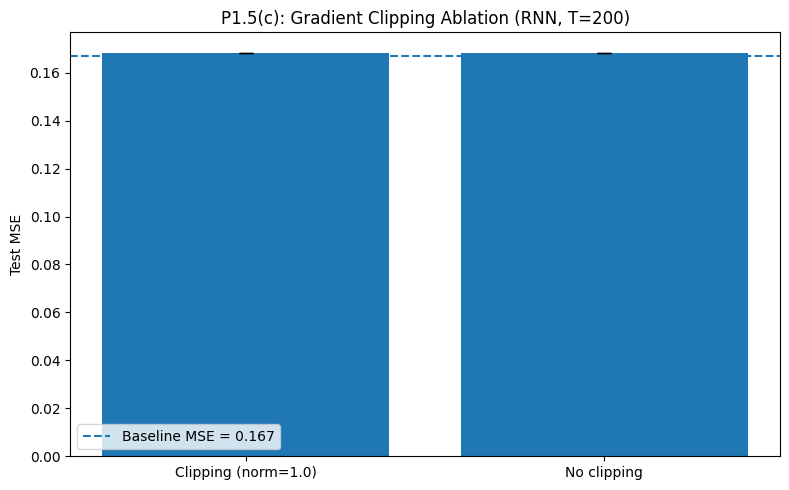

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

ablation = df[df["problem"] == "P1.5c_GradientClipping"].copy()

ablation["configuration"] = ablation["notes"].apply(
    lambda x: "Clipping (norm=1.0)" if "Clipping (norm=1.0)" in x
    else "No clipping"
)

summary = ablation.groupby("configuration")["test_mse"].agg(
    ["mean", "std"]
)

print(summary)

plt.figure(figsize=(8, 5))

plt.bar(
    summary.index,
    summary["mean"],
    yerr=summary["std"],
    capsize=5
)

plt.axhline(
    0.167,
    linestyle="--",
    label="Baseline MSE = 0.167"
)

plt.ylabel("Test MSE")
plt.title("P1.5(c): Gradient Clipping Ablation (RNN, T=200)")
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURES_DIR/"p15c_gradient_clipping.png",
    dpi=300
)

plt.show()

In [ ]:
# ==========================================
# P1.5(b): HAR HIDDEN-SIZE SWEEP
# LSTM AND GRU | 3 SEEDS
# ==========================================

from sklearn.metrics import accuracy_score, f1_score
import time
import numpy as np
import pandas as pd
import torch

HAR_HIDDEN_SIZES = [16, 32, 64, 128]
HAR_SWEEP_MODELS = ["LSTM", "GRU"]

har_hidden_sweep_results = []

for model_name in HAR_SWEEP_MODELS:

    for hidden_size in HAR_HIDDEN_SIZES:

        for seed_value, exp in har_experiments.items():

            print("\n" + "=" * 65)
            print(
                f"Model={model_name} | Hidden={hidden_size} "
                f"| Seed={seed_value}"
            )
            print("=" * 65)

            # Seed before model initialization
            set_seed(seed_value)

            model = HARSequenceClassifier(
                cell_type=model_name,
                input_size=9,
                hidden_size=hidden_size,
                num_classes=6,
                dropout=0.3
            ).to(device)

            params = sum(
                p.numel()
                for p in model.parameters()
                if p.requires_grad
            )

            start_time = time.time()

            model, history = train_har_model(
                model=model,
                train_x=exp["X_train"],
                train_y=exp["y_train"],
                val_x=exp["X_val"],
                val_y=exp["y_val"],
                seed=seed_value,
                epochs=20,
                batch_size=64,
                learning_rate=0.001,
                patience=20
            )

            # Test evaluation
            model.eval()

            test_x = torch.tensor(
                exp["X_test"],
                dtype=torch.float32
            )

            test_loader = DataLoader(
                TensorDataset(test_x),
                batch_size=64,
                shuffle=False
            )

            predictions = []

            with torch.no_grad():
                for (batch_x,) in test_loader:

                    batch_x = batch_x.to(device)

                    outputs = model(batch_x)

                    predictions.extend(
                        outputs.argmax(dim=1).cpu().numpy()
                    )

            y_pred = np.array(predictions)
            y_true = exp["y_test"]

            accuracy = accuracy_score(y_true, y_pred)

            macro_f1 = f1_score(
                y_true,
                y_pred,
                average="macro"
            )

            seconds_per_epoch = np.mean(
                history["epoch_time"]
            )

            result = {
                "Model": model_name,
                "Hidden Size": hidden_size,
                "Seed": seed_value,
                "Test Accuracy": accuracy,
                "Macro F1": macro_f1,
                "Parameters": params,
                "Seconds per Epoch": seconds_per_epoch,
                "Epochs": len(history["train_loss"])
            }

            har_hidden_sweep_results.append(result)

            print(f"Accuracy: {accuracy:.4f}")
            print(f"Macro F1: {macro_f1:.4f}")
            print(f"Parameters: {params}")
            print(f"Seconds per epoch: {seconds_per_epoch:.2f}")

print("\nAll 24 HAR hidden-size experiments completed!")


Model=LSTM | Hidden=16 | Seed=42
Epoch 01/20 | Train Loss: 1.5735 | Val Loss: 1.3641 | Time: 5.78s
Epoch 02/20 | Train Loss: 1.1492 | Val Loss: 1.0081 | Time: 4.67s
Epoch 03/20 | Train Loss: 0.9129 | Val Loss: 0.8754 | Time: 6.03s
Epoch 04/20 | Train Loss: 0.7953 | Val Loss: 0.8172 | Time: 4.84s
Epoch 05/20 | Train Loss: 0.7238 | Val Loss: 0.7834 | Time: 4.61s
Epoch 06/20 | Train Loss: 0.7771 | Val Loss: 0.8601 | Time: 6.42s
Epoch 07/20 | Train Loss: 0.7187 | Val Loss: 0.7774 | Time: 4.69s
Epoch 08/20 | Train Loss: 0.6726 | Val Loss: 0.8022 | Time: 4.56s
Epoch 09/20 | Train Loss: 0.6584 | Val Loss: 0.7827 | Time: 6.27s
Epoch 10/20 | Train Loss: 0.6459 | Val Loss: 0.7699 | Time: 4.59s
Epoch 11/20 | Train Loss: 0.6330 | Val Loss: 0.8150 | Time: 4.76s
Epoch 12/20 | Train Loss: 0.6235 | Val Loss: 0.7978 | Time: 6.28s
Epoch 13/20 | Train Loss: 0.6073 | Val Loss: 0.8075 | Time: 4.60s
Epoch 14/20 | Train Loss: 0.5973 | Val Loss: 0.7914 | Time: 5.11s
Epoch 15/20 | Train Loss: 0.5874 | Val Los

In [ ]:
print("Completed HAR sweep runs:", len(har_hidden_sweep_results))

import pandas as pd

har_sweep_df = pd.DataFrame(har_hidden_sweep_results)

print("\nResults preview:")
display(har_sweep_df.head())

print("\nRuns per model and hidden size:")
print(
    har_sweep_df.groupby(["Model", "Hidden Size"]).size()
)

Completed HAR sweep runs: 24

Results preview:


,Model,Hidden Size,Seed,Test Accuracy,Macro F1,Parameters,Seconds per Epoch,Epochs
0,LSTM,16,42,0.755344,0.742704,1830,5.241543,20
1,LSTM,16,123,0.795046,0.790847,1830,5.151082,20
2,LSTM,16,2026,0.676960,0.654786,1830,5.208742,20
3,LSTM,32,42,0.868680,0.867992,5702,5.851381,20
4,LSTM,32,123,0.881574,0.881502,5702,5.840561,20



Runs per model and hidden size:
Model  Hidden Size
GRU    16             3
       32             3
       64             3
       128            3
LSTM   16             3
       32             3
       64             3
       128            3
dtype: int64


In [ ]:
df_final = pd.read_csv(RESULTS_FILE)

print("Final rows:", len(df_final))
print(df_final["problem"].value_counts())

Final rows: 76
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         1
Name: count, dtype: int64


In [ ]:
import os
import pandas as pd

print("CSV exists:", os.path.exists(RESULTS_FILE))

df = pd.read_csv(RESULTS_FILE)
print("Existing rows:", len(df))
print(df["problem"].value_counts())

CSV exists: True
Existing rows: 76
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         1
Name: count, dtype: int64


In [ ]:
import pandas as pd
import os
import shutil

# Read existing CSV
df_old = pd.read_csv(RESULTS_FILE)

# Convert HAR sweep results to assignment CSV format
new_rows = []

for r in har_hidden_sweep_results:
    new_rows.append({
        "problem": "P1.5b_HARHiddenSweep",
        "model": f"{r['Model']}_h{r['Hidden Size']}",
        "seed": r["Seed"],
        "seq_len": 128,
        "test_acc": r["Test Accuracy"],
        "macro_f1": r["Macro F1"],
        "test_mse": None,
        "params": r["Parameters"],
        "sec_per_epoch": r["Seconds per Epoch"],
        "val_loss_nats": None,
        "bits_per_char": None,
        "notes": f"hidden_size={r['Hidden Size']}; epochs={r['Epochs']}"
    })

df_new = pd.DataFrame(new_rows, columns=df_old.columns)

# Check before saving
assert len(df_new) == 24
assert len(har_hidden_sweep_results) == 24

# Backup original CSV once
backup_path = BASE_DIR / "results_backup_before_HAR_sweep.csv"

if not os.path.exists(backup_path):
    shutil.copy2(RESULTS_FILE, backup_path)

# Avoid duplicates if saving cell is run again
existing_keys = set(
    zip(df_old["problem"], df_old["model"], df_old["seed"])
)

new_keys = list(zip(df_new["problem"], df_new["model"], df_new["seed"]))

df_new = df_new[
    [key not in existing_keys for key in new_keys]
]

# Append and save
df_final = pd.concat([df_old, df_new], ignore_index=True)
df_final.to_csv(RESULTS_FILE, index=False)

print("New rows added:", len(df_new))
print("Final CSV rows:", len(df_final))
print("Backup:", backup_path)

New rows added: 24
Final CSV rows: 100
Backup: /content/drive/MyDrive/ML_Assignment/results_backup_before_HAR_sweep.csv


/tmp/ipykernel_20422/2869744275.py:53: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_final = pd.concat([df_old, df_new], ignore_index=True)


In [ ]:
df_final = pd.read_csv(RESULTS_FILE)

print("Final rows:", len(df_final))
print(df_final["problem"].value_counts())

Final rows: 100
problem
P1.4_Adding               36
P1.5b_HiddenSweep         24
P1.5b_HARHiddenSweep      24
P1.3_HAR                   9
P1.5c_GradientClipping     6
P1.5a_GradientFlow         1
Name: count, dtype: int64


In [ ]:
import pandas as pd

# Load the saved HAR hidden-size results
har_results = pd.read_csv(RESULTS_FILE)

har_results = har_results[
    har_results["problem"] == "P1.5b_HARHiddenSweep"
].copy()

# Extract hidden size from model name
har_results["hidden_size"] = (
    har_results["model"].str.extract(r"_h(\d+)").astype(int)
)

# Calculate mean and standard deviation across seeds
summary = har_results.groupby(
    ["hidden_size", "model"]
).agg(
    mean_accuracy=("test_acc", "mean"),
    std_accuracy=("test_acc", "std"),
    mean_macro_f1=("macro_f1", "mean"),
    std_macro_f1=("macro_f1", "std"),
    parameters=("params", "mean"),
    seconds_per_epoch=("sec_per_epoch", "mean")
).reset_index()

display(summary.round(4))

,hidden_size,model,mean_accuracy,std_accuracy,mean_macro_f1,std_macro_f1,parameters,seconds_per_epoch
0,16,GRU_h16,0.8903,0.0090,0.8908,0.0098,1398.0,5.6470
1,16,LSTM_h16,0.7424,0.0601,0.7294,0.0690,1830.0,5.2005
2,32,GRU_h32,0.8972,0.0070,0.8971,0.0064,4326.0,6.2744
3,32,LSTM_h32,0.8818,0.0132,0.8818,0.0139,5702.0,5.8557
4,64,GRU_h64,0.8879,0.0078,0.8881,0.0082,14790.0,8.4715
5,64,LSTM_h64,0.8800,0.0080,0.8802,0.0085,19590.0,8.6524
6,128,GRU_h128,0.9061,0.0017,0.9062,0.0018,54150.0,13.8601
7,128,LSTM_h128,0.8756,0.0423,0.8733,0.0472,71942.0,15.5060


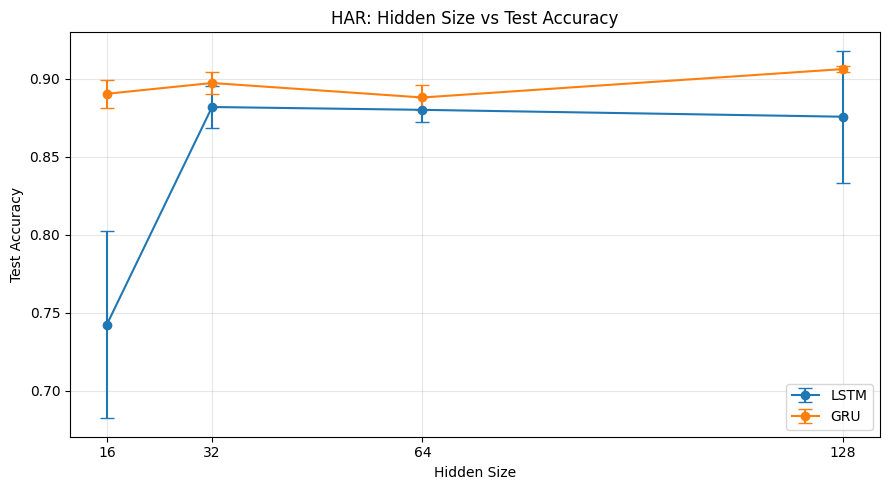

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for model_name in ["LSTM_h", "GRU_h"]:
    data = summary[
        summary["model"].str.startswith(model_name)
    ].sort_values("hidden_size")

    plt.errorbar(
        data["hidden_size"],
        data["mean_accuracy"],
        yerr=data["std_accuracy"],
        marker="o",
        capsize=5,
        label=model_name.replace("_h", "")
    )

plt.xlabel("Hidden Size")
plt.ylabel("Test Accuracy")
plt.title("HAR: Hidden Size vs Test Accuracy")
plt.xticks([16, 32, 64, 128])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "P1_5b_HAR_hidden_size_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
summary.to_csv(
    BASE_DIR / "P1_5b_HAR_hidden_size_summary.csv",
    index=False
)

print("Summary table saved successfully!")

Summary table saved successfully!


In [ ]:
print("Training function available:",
      callable(train_adding_model))

print("Dataset available:",
      100 in adding_datasets)

Training function available: True
Dataset available: True


## P1.5(d): Analysis and Discussion

### 1. Gradient Flow and Memory

In a normal RNN, it becomes difficult to remember information from earlier time steps when the sequence is very long. During training, gradients can become very small. This is called the vanishing gradient problem.

LSTM and GRU handle this problem better because they use gates to decide what information should be remembered and what can be forgotten.

### 2. Effect of Sequence Length

When the sequence length increases, the model has to remember information for a longer time. This makes learning more difficult, especially for a normal RNN.

LSTM and GRU are generally better at handling long sequences because their gates help them keep important information for longer.

### 3. Effect of Gradient Clipping

I compared a vanilla RNN with and without gradient clipping for T=200 using three different seeds.

The average test MSE was:
- With clipping: 0.168307
- Without clipping: 0.168284

Both results are almost the same. Gradient clipping did not improve the average test result, but it gave slightly more consistent results across the three runs.

### 4. Accuracy, Model Size and Training Time

From the HAR hidden-size experiment, I observed that increasing the hidden size does not always give a big improvement in accuracy.

GRU with hidden size 128 gave the highest average accuracy of 90.61%. It had 54,150 parameters and took around 13.86 seconds per epoch.

GRU with hidden size 16 gave 89.03% accuracy with only 1,398 parameters and took around 5.65 seconds per epoch.

This shows that a bigger model can give better accuracy, but it also needs more time and memory.

### 5. Recommendation for Wearable Devices

For wearable devices, I would prefer GRU because it gave good accuracy with fewer parameters than LSTM in our experiments.

Wearable devices have limited battery, memory and processing power. So, a smaller GRU model can be a good choice because it is lighter and still gives good performance.

### Conclusion

From these experiments, I learned that RNN, LSTM and GRU behave differently when working with sequential data. LSTM and GRU can remember important information for longer sequences more effectively than a normal RNN.

I also observed that gradient clipping did not make a major difference in the final test MSE in my experiment. Finally, choosing a model depends not only on accuracy but also on its size and training time.